# 🌊 FloodSense — Practicals 4 to 10 in one notebook
### Computational Intelligence Laboratory (CELBC710) · Flood-risk intelligent system

This notebook builds the complete system **from raw data to a validated, explainable, deployed AI system**, following the syllabus Tasks 4 → 10 in order. Every number, table and chart below is produced live by the code.

| Task | What happens here | Learning outcome |
|:---:|---|:---:|
| **4** | Load, explore, audit and clean the dataset | LO 2.1 |
| **5** | Engineer, encode, scale and select features; split by time | LO 2.2 |
| **6** | Train and compare ML models, error analysis, **SHAP**, clustering | LO 2.3 |
| **7** | Design, tune and train an **LSTM** against a dense baseline | LO 3.1 |
| **8** | Interpret the LSTM: permutation, time-step ablation, activations, **SHAP** | LO 3.2 |
| **9** | Integrate **DL → ML → AI rules** into one end-to-end system | LO 4.1 |
| **10** | Validate on unseen days, explain decisions, ethics & bias, deployment | LO 4.2 |

**How to run in Google Colab:** `Runtime → Run all`. No GPU and no uploads are needed: the dataset is downloaded automatically from the project's GitHub repository. A full run takes about 3–5 minutes.

> **The problem in one sentence:** given 7 consecutive days of weather and satellite readings for one monitored location, decide whether the **last** day is a flood day, and explain why.

In [1]:
#@title ⚙️ Setup: install SHAP if needed, import libraries, set a consistent visual style
import importlib.util, subprocess, sys, warnings
warnings.filterwarnings("ignore")
if importlib.util.find_spec("shap") is None:
    print("Installing SHAP…")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)

import io, json, random, warnings, zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import shap
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()
DEVICE = torch.device("cpu")  # the model is small: CPU keeps runs reproducible and SHAP-compatible

C = {"blue": "#0B6BCB", "red": "#D93A3A", "orange": "#E8820C", "green": "#1A9E5C",
     "purple": "#7A5AF8", "grey": "#8C9AAB", "ink": "#0F2235", "light": "#EEF4FB"}
ADVISORY_COLORS = {"LOW RISK": C["green"], "MONITOR": C["blue"],
                   "FLOOD WATCH": C["orange"], "FLOOD WARNING": C["red"]}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "axes.edgecolor": "#B8C4D0", "axes.labelcolor": C["ink"], "font.size": 10, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[C["blue"], C["orange"], C["green"], C["red"], C["purple"], C["grey"]]),
})

OUT = Path("floodsense_outputs"); OUT.mkdir(exist_ok=True)

def save(fig, name):
    """Keep a PNG copy of every figure for the practical record."""
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")

def findings(title, points):
    """Show computed findings as a highlighted note."""
    display(Markdown(f"> **🔎 {title}**\n>\n" + "\n".join(f"> - {p}" for p in points)))

def table(df, gradient=None, precision=3, formats=None):
    """Consistently formatted table; optional blue shading on the given columns."""
    styler = df.style.format(formats, precision=precision)
    if gradient:
        styler = styler.background_gradient(cmap="Blues", subset=gradient)
    return styler

CM_CMAP = LinearSegmentedColormap.from_list("floodsense", ["#FFFFFF", C["blue"]])
def plot_cm(ax, y_true, y_pred, title):
    """Confusion matrix with plain-language cell names."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(cm.max(), 1))
    names = [["Correct calm", "False alarm"], ["Missed flood", "Caught flood"]]
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > 0.6 * cm.max() else C["ink"]
            ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                    color=color, fontsize=9.5, fontweight="bold")
    ax.set_xticks([0, 1], ["No Flood", "Flood"]); ax.set_yticks([0, 1], ["No Flood", "Flood"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title); ax.grid(False)

def scores(y_true, prob, threshold=0.5, pred=None):
    """Standard flood-class metrics (Flood = positive class)."""
    pred = (prob >= threshold).astype(int) if pred is None else pred
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, prob) if prob is not None else np.nan}

print(f"Ready · PyTorch {torch.__version__} · scikit-learn {__import__('sklearn').__version__} · SHAP {shap.__version__}")

Ready · PyTorch 2.15.0+cpu · scikit-learn 1.8.0 · SHAP 0.54.1


---
## Task 4 · Load, explore and clean the data
> **Syllabus:** load a real-world dataset; examine structure, feature types, distributions and summary statistics; handle missing values, duplicates and outliers; visualise patterns; prepare a cleaned dataset. *(LO 2.1)*

### 4.1 Load the dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Stavan1234/FloodSense/main/input_data/flood_dataset.csv"

def load_dataset():
    """Use a local copy if present, otherwise download from GitHub, otherwise ask for an upload (Colab)."""
    for path in [Path("flood_dataset.csv"), Path("input_data/flood_dataset.csv"), Path("/content/flood_dataset.csv")]:
        if path.exists():
            return pd.read_csv(path), str(path)
    try:
        return pd.read_csv(DATA_URL), "GitHub · Stavan1234/FloodSense"
    except Exception as exc:
        print(f"Download failed ({exc}); please upload flood_dataset.csv.")
    from google.colab import files
    uploaded = files.upload()
    name = next(iter(uploaded))
    return pd.read_csv(io.BytesIO(uploaded[name])), name

raw, source = load_dataset()
TARGET = "flood_event"
print(f"Source: {source}")
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns · {raw['date'].min()} → {raw['date'].max()}")
display(raw.head())

Source: input_data\flood_dataset.csv
1,364 rows × 25 columns · 2022-01-01 → 2025-09-25


,date,elevation,evaporation,latitude,longitude,precipitation,pressure,soil_moisture,temperature,water_area_km2,wind_speed,humidity,precip_3day_avg,precip_7day_avg,temp_3day_avg,soil_3day_avg,day_of_year,month,year,is_monsoon,water_area_change,water_area_pct_change,days_since_last_flood,flood_event,soil_type
0,2022-01-01,109.19,0.129097,19.0,73.0,0.000010,99544.871625,0.079300,32.258430,936.216559,5.330860,NaN,0.000010,0.000010,33.013244,0.079300,1,2,2022,0,668.119195,invalid,0,1,loam
1,2022-01-02,109.19,0.091713,19.0,73.0,0.080685,100053.178557,0.085906,23.735387,442.841604,5.984159,41.539870,0.040348,0.040348,31.002921,0.082603,2,10,2022,0,-273.701157,invalid,5,0,NaN
2,2022-01-03,109.19,0.122675,19.0,73.0,0.028645,99408.952829,0.079300,15.207445,178.267467,5.284783,68.307940,0.036447,0.036447,28.609926,0.081502,3,8,2022,1,-295.383214,invalid,9,0,loam
3,2022-01-04,109.19,0.102339,19.0,73.0,0.139185,100410.555372,0.081031,19.193493,993.130148,4.434671,53.630416,0.082839,0.062131,26.047427,0.082079,4,6,2022,1,-253.671503,invalid,1,0,loam
4,2022-01-05,109.19,0.062928,19.0,73.0,0.010797,99228.698504,0.103815,27.059734,342.375757,6.362610,42.593444,0.059542,0.051865,27.414540,0.088048,5,6,2022,1,464.191557,invalid,0,1,sandy


### 4.2 Structure and feature types

In [3]:
overview = pd.DataFrame({
    "Type": raw.dtypes.astype(str),
    "Non-missing": raw.notna().sum(),
    "Unique values": raw.nunique(),
    "Example": raw.iloc[0].astype(str),
})
overview["Kind"] = np.select(
    [overview.index == TARGET, overview.index == "date", overview["Type"].isin(["object", "str", "string"])],
    ["Target (what we predict)", "Date", "Text / category"], default="Number")
display(overview)

,Type,Non-missing,Unique values,Example,Kind
date,str,1364,1364,2022-01-01,Date
elevation,float64,1364,1,109.19,Number
evaporation,float64,1364,1364,0.1290969308096624,Number
latitude,float64,1364,1,19.0,Number
longitude,float64,1364,1,73.0,Number
precipitation,float64,1364,1364,1.037424447519706e-05,Number
pressure,float64,1364,1364,99544.8716246093,Number
soil_moisture,float64,1364,834,0.0793,Number
temperature,float64,1364,1364,32.258430148422946,Number
water_area_km2,float64,1364,1235,936.2165589010057,Number


### 4.3 Data-quality audit
Before changing anything, list every problem the data has and decide what to do about it.

In [4]:
dates = pd.to_datetime(raw["date"], errors="coerce")
missing = raw.isna().sum()
constant_cols = [c for c in raw.select_dtypes("number").columns if raw[c].nunique(dropna=True) <= 1]
text_in_numeric = raw["water_area_pct_change"].astype(str).unique().tolist()
bad_humidity = int((~raw["humidity"].between(0, 100) & raw["humidity"].notna()).sum())
month_mismatch = int((pd.to_numeric(raw["month"], errors="coerce") != dates.dt.month).sum())
gaps = int((dates.sort_values().diff().dt.days.dropna() != 1).sum())

audit = pd.DataFrame([
    ["Missing cells", int(missing.sum()), ", ".join(f"{c} ({n})" for c, n in missing[missing > 0].items()) or "none",
     "Fill from the previous day (readings) / most common value (soil type)"],
    ["Duplicate rows", int(raw.duplicated().sum()), "exact copies", "Drop"],
    ["Date gaps or duplicates", gaps + int(dates.duplicated().sum()), "daily series must be continuous", "Required for 7-day windows"],
    ["Constant columns", len(constant_cols), ", ".join(constant_cols), "Drop: no information (single location)"],
    ["Text in a numeric column", len(text_in_numeric), f"water_area_pct_change = {text_in_numeric}", "Drop the column"],
    ["Impossible humidity (below 0 % or above 100 %)", bad_humidity, "physically invalid readings", "Treat as missing"],
    ["Stored month disagrees with date", month_mismatch, "calendar helper columns are unreliable", "Rebuild season features from the date"],
], columns=["Check", "Count", "Details", "Action"])
display(audit.style.hide(axis="index"))

Check,Count,Details,Action
Missing cells,2,"humidity (1), soil_type (1)",Fill from the previous day (readings) / most common value (soil type)
Duplicate rows,0,exact copies,Drop
Date gaps or duplicates,0,daily series must be continuous,Required for 7-day windows
Constant columns,3,"elevation, latitude, longitude",Drop: no information (single location)
Text in a numeric column,1,water_area_pct_change = ['invalid'],Drop the column
Impossible humidity (below 0 % or above 100 %),3,physically invalid readings,Treat as missing
Stored month disagrees with date,1262,calendar helper columns are unreliable,Rebuild season features from the date


### 4.4 Summary statistics

In [5]:
ENV = ["precipitation", "soil_moisture", "temperature", "humidity", "pressure", "wind_speed", "evaporation",
       "water_area_km2", "water_area_change", "precip_3day_avg", "precip_7day_avg", "temp_3day_avg", "soil_3day_avg"]
stats = raw[ENV].describe().T
stats["skew"] = raw[ENV].skew()
display(table(stats, gradient=["skew"]))

,count,mean,std,min,25%,50%,75%,max,skew
precipitation,1364.000,0.095,0.148,0.000,0.005,0.034,0.123,1.342,2.940
soil_moisture,1364.000,0.089,0.013,0.079,0.079,0.084,0.095,0.160,1.607
temperature,1364.000,26.707,6.086,7.420,22.688,26.597,30.800,46.401,0.095
humidity,1363.000,50.394,16.337,-12.205,39.576,50.296,61.267,99.610,-0.048
pressure,1364.000,99559.063,753.141,96918.209,99065.294,99560.148,100062.301,102554.265,-0.033
wind_speed,1364.000,3.465,1.970,0.101,1.713,3.434,5.154,7.000,0.075
evaporation,1364.000,0.099,0.030,0.008,0.080,0.098,0.119,0.199,0.009
water_area_km2,1364.000,601.195,415.212,0.000,285.675,582.472,883.635,2421.849,0.456
water_area_change,1364.000,18.120,296.914,-1268.454,-180.471,11.407,219.295,936.724,-0.070
precip_3day_avg,1364.000,0.095,0.087,0.000,0.030,0.070,0.135,0.625,1.739


### 4.5 Visual exploration
Four views: class balance and seasonality, how each reading differs between flood and normal days, how readings relate to each other, and where the outliers are.

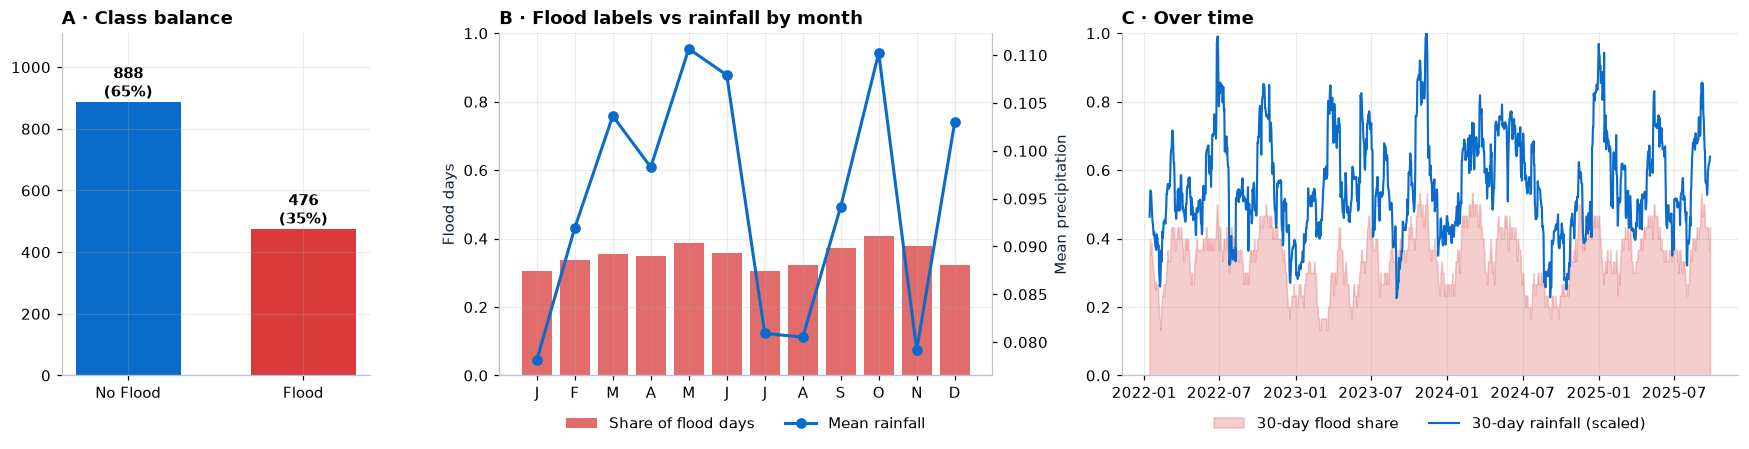

In [6]:
eda = raw.assign(date=dates).dropna(subset=["date"]).sort_values("date")
eda["month"] = eda["date"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 2]})
counts = eda[TARGET].value_counts().reindex([0, 1])
axes[0].bar(["No Flood", "Flood"], counts.values, color=[C["blue"], C["red"]], width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v}\n({v / counts.sum():.0%})", ha="center", va="bottom", fontweight="bold")
axes[0].set_title("A · Class balance"); axes[0].set_ylim(0, counts.max() * 1.25)

monthly = eda.groupby("month").agg(flood_rate=(TARGET, "mean"), rain=("precipitation", "mean"))
axes[1].bar(monthly.index, monthly["flood_rate"], color=C["red"], alpha=0.75, label="Share of flood days")
axes[1].set_ylim(0, 1); axes[1].set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[1].set_ylabel("Flood days"); axes[1].set_title("B · Flood labels vs rainfall by month")
ax2 = axes[1].twinx(); ax2.plot(monthly.index, monthly["rain"], color=C["blue"], marker="o", lw=2, label="Mean rainfall")
ax2.set_ylabel("Mean precipitation"); ax2.grid(False); ax2.spines["right"].set_visible(True)
handles = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
axes[1].legend(handles, [h.get_label() for h in handles], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)

roll = eda.set_index("date")[[TARGET, "precipitation"]].rolling("30D", min_periods=14).mean()
axes[2].fill_between(roll.index, roll[TARGET], color=C["red"], alpha=0.25, label="30-day flood share")
axes[2].plot(roll.index, roll["precipitation"] / roll["precipitation"].max(), color=C["blue"], lw=1.4, label="30-day rainfall (scaled)")
axes[2].set_title("C · Over time"); axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2); axes[2].set_ylim(0, 1)
fig.tight_layout(); save(fig, "task4_overview"); plt.show()

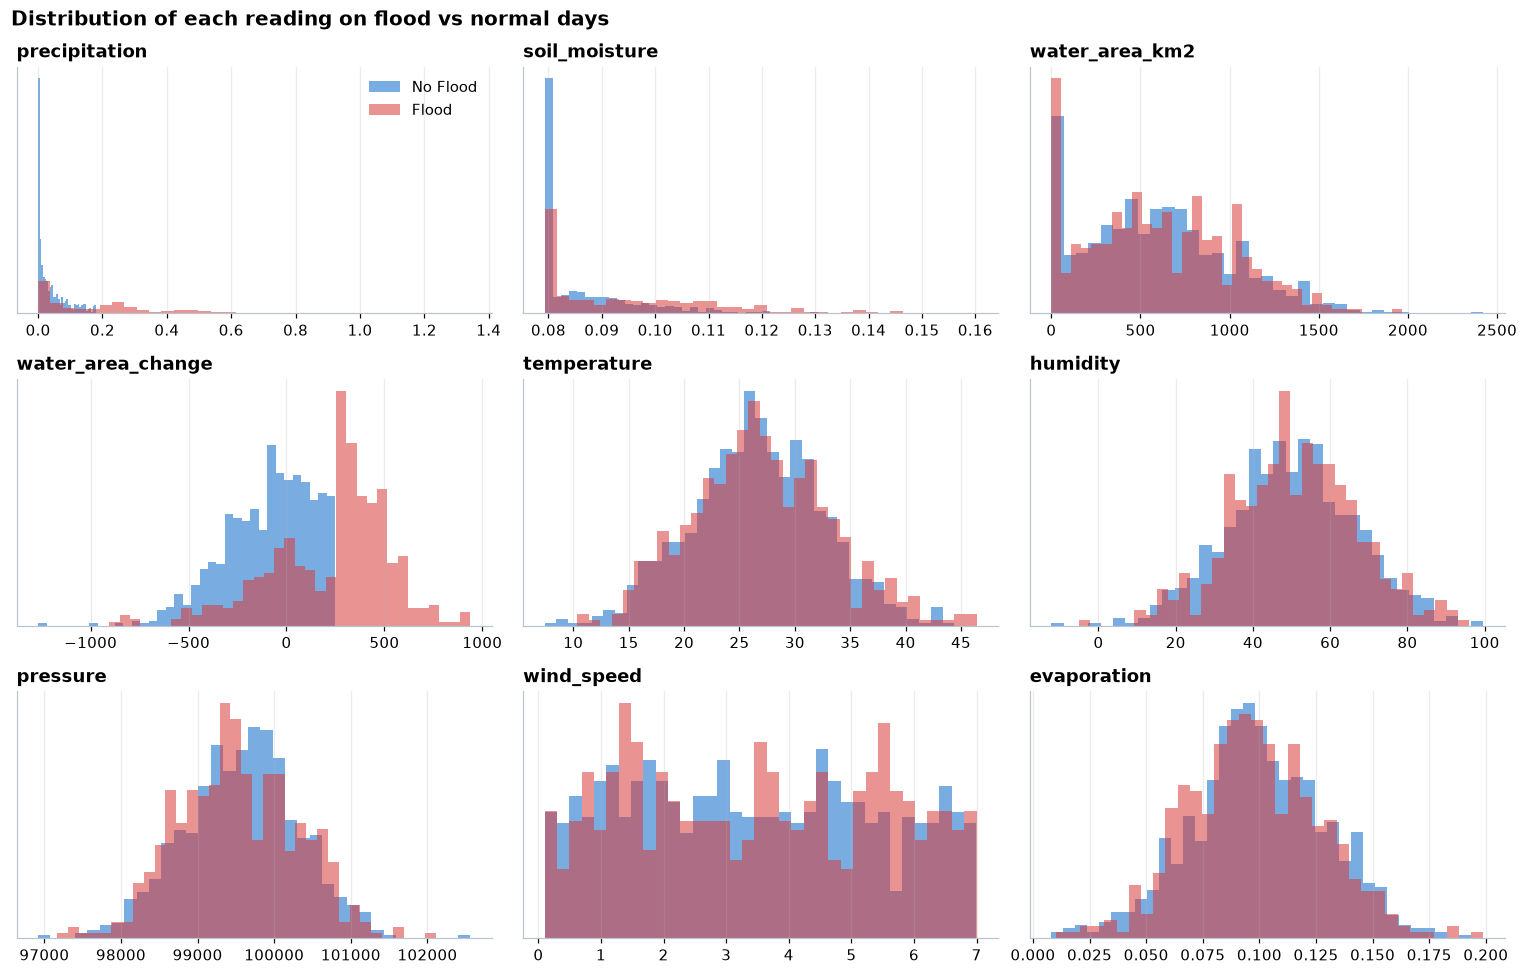

In [7]:
key = ["precipitation", "soil_moisture", "water_area_km2", "water_area_change", "temperature",
       "humidity", "pressure", "wind_speed", "evaporation"]
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), key):
    for label, color, name in [(0, C["blue"], "No Flood"), (1, C["red"], "Flood")]:
        ax.hist(eda.loc[eda[TARGET] == label, col].dropna(), bins=35, density=True, alpha=0.55, color=color, label=name)
    ax.set_title(col); ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Distribution of each reading on flood vs normal days", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(); save(fig, "task4_distributions"); plt.show()

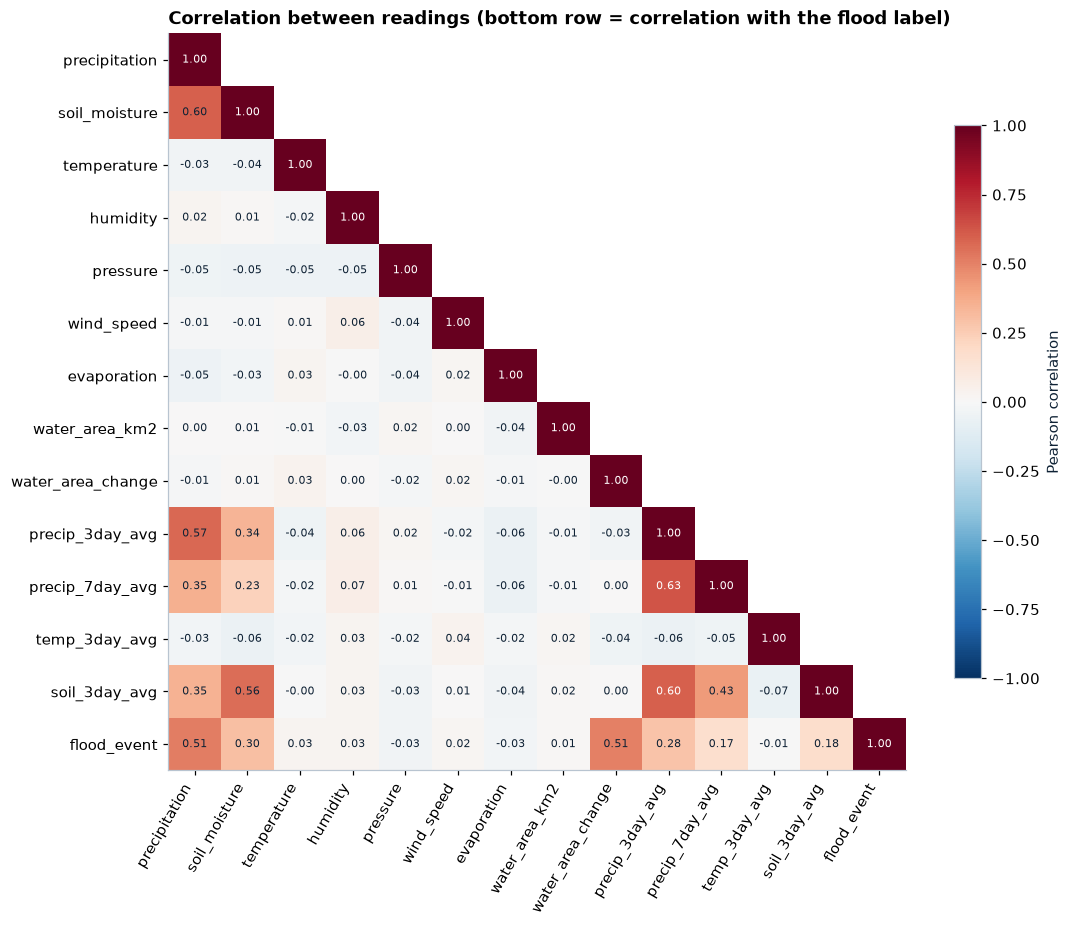

In [8]:
corr = eda[ENV + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10.5, 8.5))
im = ax.imshow(np.ma.masked_where(mask, corr), cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else C["ink"])
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson correlation")
ax.set_title("Correlation between readings (bottom row = correlation with the flood label)")
fig.tight_layout(); save(fig, "task4_correlation"); plt.show()

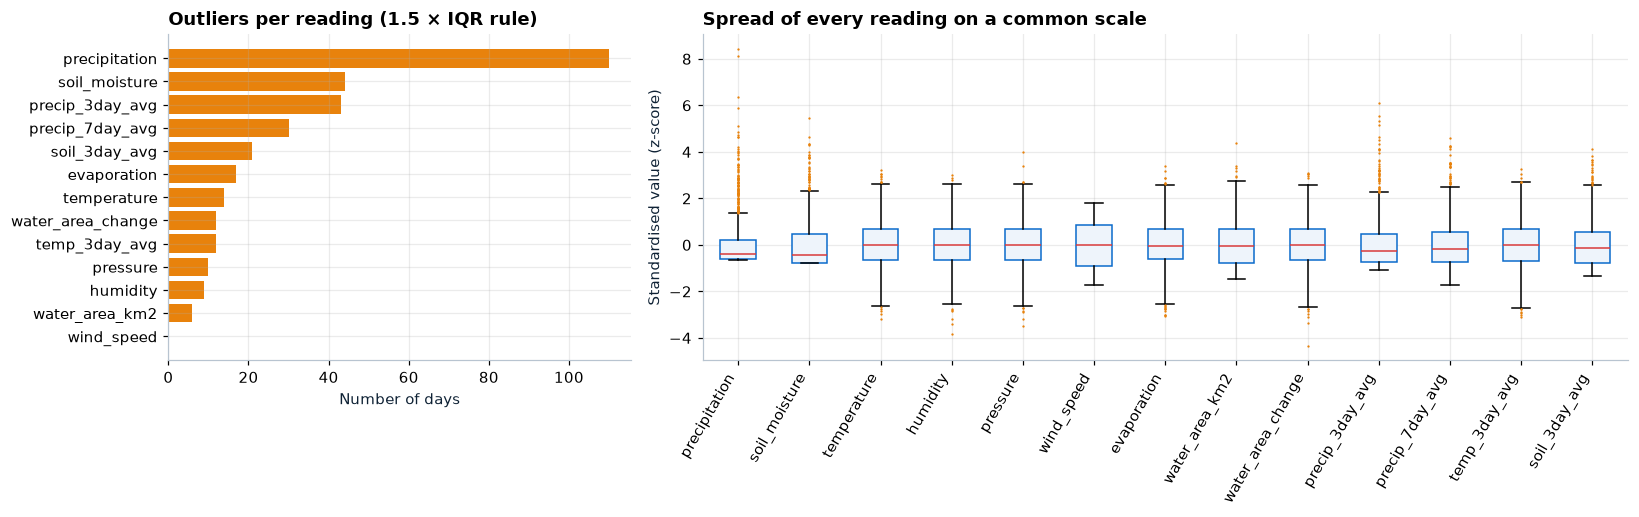

In [9]:
q1, q3 = eda[ENV].quantile(0.25), eda[ENV].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((eda[ENV] < q1 - 1.5 * iqr) | (eda[ENV] > q3 + 1.5 * iqr)).sum().sort_values()
z = (eda[ENV] - eda[ENV].mean()) / eda[ENV].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh(outlier_counts.index, outlier_counts.values, color=C["orange"])
axes[0].set_title("Outliers per reading (1.5 × IQR rule)"); axes[0].set_xlabel("Number of days")
axes[1].boxplot([z[c].dropna() for c in ENV], patch_artist=True,
                boxprops=dict(facecolor=C["light"], color=C["blue"]), medianprops=dict(color=C["red"]),
                flierprops=dict(marker=".", markersize=3, markerfacecolor=C["orange"], markeredgecolor="none"))
axes[1].set_xticks(range(1, len(ENV) + 1), ENV, rotation=60, ha="right"); axes[1].set_ylabel("Standardised value (z-score)")
axes[1].set_title("Spread of every reading on a common scale")
fig.tight_layout(); save(fig, "task4_outliers"); plt.show()

### 4.6 Clean the dataset
Each step is logged with the number of cells or rows it touched. **Outliers are kept on purpose:** extreme rainfall and sudden water rises are exactly the events a flood system must see. Removing them would hide floods. Scaling is done in Task 5, *after* the time split, so test data never influences it.

In [10]:
log = []
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
before = len(df)
df = df.dropna(subset=["date"]).drop_duplicates().sort_values("date").reset_index(drop=True)
log.append(("Parse dates, sort, drop duplicate rows", before - len(df), "rows removed"))

drop_cols = constant_cols + ["water_area_pct_change", "month", "day_of_year", "year", "is_monsoon"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])
log.append(("Drop constant, text-only and unreliable calendar columns", len(drop_cols), "columns removed"))

invalid = ~df["humidity"].between(0, 100) & df["humidity"].notna()
df.loc[invalid, "humidity"] = np.nan
log.append(("Mark impossible humidity values as missing", int(invalid.sum()), "cells"))

n_missing = int(df[ENV].isna().sum().sum())
df[ENV] = df[ENV].ffill().bfill()          # previous day's reading: uses only past information
log.append(("Fill missing readings from the previous day", n_missing, "cells"))

n_soil = int(df["soil_type"].isna().sum())
df["soil_type"] = df["soil_type"].fillna(df["soil_type"].mode()[0])
log.append(("Fill missing soil type with the most common type", n_soil, "cells"))

df[TARGET] = df[TARGET].astype(int)
assert df[ENV].isna().sum().sum() == 0 and df["date"].diff().dropna().dt.days.eq(1).all()

display(pd.DataFrame(log, columns=["Cleaning step", "Affected", "Unit"]).style.hide(axis="index"))
df.to_csv(OUT / "task4_clean_dataset.csv", index=False)
print(f"Clean dataset: {df.shape[0]:,} rows × {df.shape[1]} columns → saved to {OUT / 'task4_clean_dataset.csv'}")

top_corr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
findings("Task 4 findings", [
    f"{len(df):,} continuous daily records ({df['date'].min():%b %Y} – {df['date'].max():%b %Y}); "
    f"{df[TARGET].mean():.0%} are labelled flood days.",
    f"All data comes from **one location** (constant {', '.join(constant_cols)}), so results cannot be generalised to other places.",
    f"Flood share is roughly the same in every month (min {monthly['flood_rate'].min():.0%}, max {monthly['flood_rate'].max():.0%}) "
    "even though real floods here cluster in the June–September monsoon. This points to **simulated or noisy labels**.",
    f"Strongest link to the label: **{top_corr.index[0]}** (|r| = {top_corr.iloc[0]:.2f}), then {top_corr.index[1]} "
    f"({top_corr.iloc[1]:.2f}).",
])

Cleaning step,Affected,Unit
"Parse dates, sort, drop duplicate rows",0,rows removed
"Drop constant, text-only and unreliable calendar columns",8,columns removed
Mark impossible humidity values as missing,3,cells
Fill missing readings from the previous day,4,cells
Fill missing soil type with the most common type,1,cells


Clean dataset: 1,364 rows × 17 columns → saved to floodsense_outputs\task4_clean_dataset.csv


> **🔎 Task 4 findings**
>
> - 1,364 continuous daily records (Jan 2022 – Sep 2025); 35% are labelled flood days.
> - All data comes from **one location** (constant elevation, latitude, longitude), so results cannot be generalised to other places.
> - Flood share is roughly the same in every month (min 31%, max 41%) even though real floods here cluster in the June–September monsoon. This points to **simulated or noisy labels**.
> - Strongest link to the label: **precipitation** (|r| = 0.51), then water_area_change (0.51).

---
## Task 5 · Feature engineering, encoding, selection and splitting
> **Syllabus:** extract, transform and encode features into an ML-ready format; select the most relevant features using statistical or model-based methods; split into training and testing sets; prepare the final feature matrix. *(LO 2.2)*

### 5.1 Create features and decide what the model may see
* **Season (cyclical):** day-of-year becomes a sine/cosine pair, so 31 December and 1 January sit next to each other.
* **Monsoon flag:** June–September, rebuilt from the real date.
* **Soil type:** one-hot encoded (clay / loam / sandy), so no false order is implied.

In [11]:
doy = df["date"].dt.dayofyear
df["day_of_year_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["day_of_year_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["is_monsoon"] = df["date"].dt.month.isin([6, 7, 8, 9]).astype(int)

SEQ_FEATURES = ENV + ["day_of_year_sin", "day_of_year_cos"]   # used by the LSTM (Tasks 7–10)
TAB_NUMERIC = SEQ_FEATURES + ["is_monsoon"]                    # used by the classical models (Task 6)
TAB_CATEGORICAL = ["soil_type"]

excluded = pd.DataFrame([
    ["flood_event", "It is the answer (target). Using it as an input would be cheating."],
    ["days_since_last_flood", "Computed from flood labels, so it can leak the answer."],
    ["water_area_pct_change", "Contains only the text 'invalid'."],
    [", ".join(constant_cols), "Same value on every row: carries no information."],
    ["month, day_of_year, year", "Stored values disagree with the date; season is rebuilt from the date instead."],
], columns=["Not used as input", "Reason"])
display(excluded.style.hide(axis="index"))
print(f"Candidate inputs: {len(TAB_NUMERIC)} numeric + {len(TAB_CATEGORICAL)} categorical")

Not used as input,Reason
flood_event,It is the answer (target). Using it as an input would be cheating.
days_since_last_flood,"Computed from flood labels, so it can leak the answer."
water_area_pct_change,Contains only the text 'invalid'.
"elevation, latitude, longitude",Same value on every row: carries no information.
"month, day_of_year, year",Stored values disagree with the date; season is rebuilt from the date instead.


Candidate inputs: 16 numeric + 1 categorical


### 5.2 Split by time: train → validation → test
Days next to each other are very similar, so a random split would let the model "peek" at the test period. We split **chronologically**: the oldest 70 % trains the models, the next 15 % tunes them, and the **latest 15 % is never touched until the final evaluation**. Every day is the last day of a 7-day window, so these exact splits are reused by the LSTM later.

Split,Days,From,To,Flood share
Train,950,2022-01-07,2024-08-13,0.342
Validation,204,2024-08-14,2025-03-05,0.343
Test (unseen),204,2025-03-06,2025-09-25,0.382


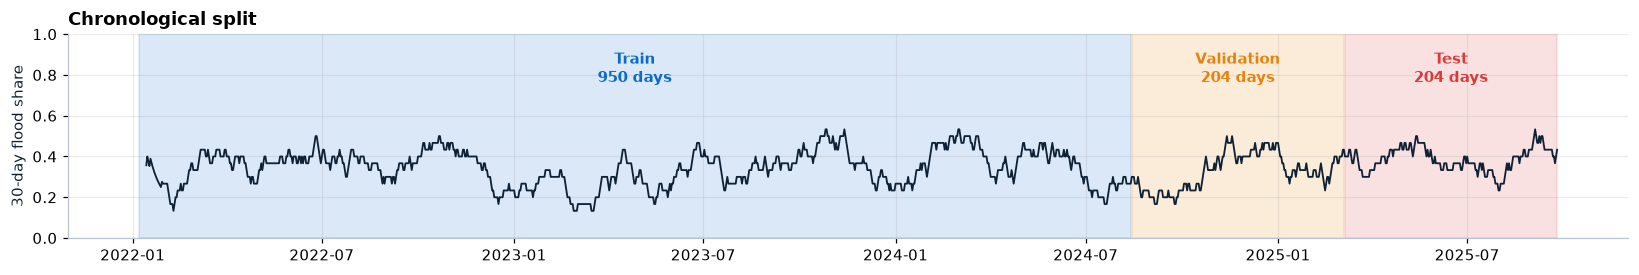

In [12]:
WINDOW = 7
TARGET_IDX = np.arange(WINDOW - 1, len(df))           # each sample = the last day of a 7-day window
n = len(TARGET_IDX); TRAIN_END, VAL_END = int(0.70 * n), int(0.85 * n)
idx_train, idx_val, idx_test = TARGET_IDX[:TRAIN_END], TARGET_IDX[TRAIN_END:VAL_END], TARGET_IDX[VAL_END:]
y_all = df[TARGET].to_numpy()
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]
dates_test = df["date"].iloc[idx_test].reset_index(drop=True)

split = pd.DataFrame([
    [name, len(ix), df["date"].iloc[ix[0]].date(), df["date"].iloc[ix[-1]].date(), y_all[ix].mean()]
    for name, ix in [("Train", idx_train), ("Validation", idx_val), ("Test (unseen)", idx_test)]
], columns=["Split", "Days", "From", "To", "Flood share"])
display(table(split).hide(axis="index"))

fig, ax = plt.subplots(figsize=(15, 2.6))
roll = df.set_index("date")[TARGET].rolling("30D", min_periods=14).mean()
ax.plot(roll.index, roll.values, color=C["ink"], lw=1.2)
for (name, ix), color in zip([("Train", idx_train), ("Validation", idx_val), ("Test", idx_test)], [C["blue"], C["orange"], C["red"]]):
    start, end = df["date"].iloc[ix[0]], df["date"].iloc[ix[-1]]
    ax.axvspan(start, end, color=color, alpha=0.15)
    ax.text(start + (end - start) / 2, 0.92, f"{name}\n{len(ix)} days", ha="center", va="top", color=color, fontweight="bold")
ax.set_ylim(0, 1); ax.set_ylabel("30-day flood share"); ax.set_title("Chronological split")
fig.tight_layout(); save(fig, "task5_split"); plt.show()

### 5.3 Impute, scale and encode, fitted on training days only
A `ColumnTransformer` fills any gaps with the training median, standardises numbers (mean 0, std 1) and one-hot encodes soil type. It **learns only from the training split** and then applies the same rules to validation and test.

In [13]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), TAB_NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), TAB_CATEGORICAL),
], verbose_feature_names_out=False)

def tab_rows(ix):
    return df.iloc[ix][TAB_NUMERIC + TAB_CATEGORICAL]

X_train_all = pd.DataFrame(preprocessor.fit_transform(tab_rows(idx_train)), columns=preprocessor.get_feature_names_out())
X_val_all = pd.DataFrame(preprocessor.transform(tab_rows(idx_val)), columns=X_train_all.columns)
X_test_all = pd.DataFrame(preprocessor.transform(tab_rows(idx_test)), columns=X_train_all.columns)
print(f"Feature matrix: train {X_train_all.shape} · validation {X_val_all.shape} · test {X_test_all.shape}")
display(X_train_all.head().round(3))

Feature matrix: train (950, 19) · validation (204, 19) · test (204, 19)


,precipitation,soil_moisture,temperature,humidity,pressure,wind_speed,evaporation,water_area_km2,water_area_change,precip_3day_avg,precip_7day_avg,temp_3day_avg,soil_3day_avg,day_of_year_sin,day_of_year_cos,is_monsoon,soil_type_clay,soil_type_loam,soil_type_sandy
0,1.995,0.518,-0.232,1.189,2.155,0.505,0.155,-1.435,-0.187,0.456,-0.046,-0.594,0.502,0.021,1.460,-0.709,0.0,1.0,0.0
1,0.251,-0.765,-1.286,0.878,0.273,-0.279,2.624,-0.630,-0.019,0.926,0.307,-0.835,-0.599,0.046,1.457,-0.709,0.0,0.0,1.0
2,-0.056,-0.765,1.634,-1.171,0.550,-0.577,1.478,1.047,-0.854,1.238,0.325,-0.454,-0.599,0.071,1.454,-0.709,0.0,0.0,1.0
3,-0.605,-0.765,2.140,-0.713,1.203,-0.561,0.725,-0.785,0.818,-0.232,0.268,-0.751,-1.357,0.095,1.450,-0.709,1.0,0.0,0.0
4,-0.638,0.019,-0.965,0.444,-1.230,-1.209,0.259,0.840,-0.427,-0.734,-0.096,-0.314,-0.894,0.120,1.445,-0.709,0.0,1.0,0.0


### 5.4 Feature selection: statistical and model-based
Two independent views of usefulness, both computed on training data only:
* **Mutual information** (statistical): how much knowing a feature reduces uncertainty about the label.
* **Random-Forest importance** (model-based): how much a feature improves the forest's splits.

Scores are scaled to 0–1 and averaged; the **top 10** features form the final matrix.

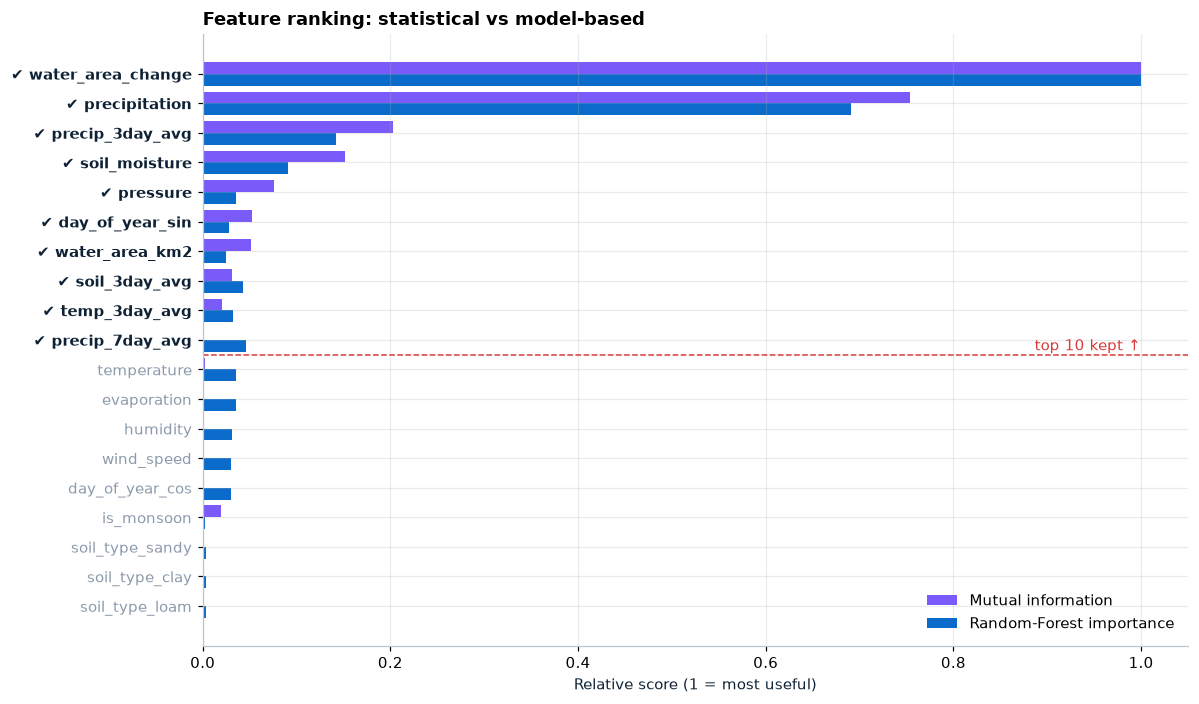

Final ML matrix: 10 features → ['water_area_change', 'precipitation', 'precip_3day_avg', 'soil_moisture', 'pressure', 'day_of_year_sin', 'water_area_km2', 'soil_3day_avg', 'temp_3day_avg', 'precip_7day_avg']


In [14]:
mi = mutual_info_classif(X_train_all, y_train, random_state=SEED)
rf_ranker = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf_ranker.fit(X_train_all, y_train)
ranking = pd.DataFrame({"Mutual information": mi, "RF importance": rf_ranker.feature_importances_}, index=X_train_all.columns)
ranking["Combined score"] = (ranking / ranking.max()).mean(axis=1)
ranking = ranking.sort_values("Combined score", ascending=False)
TOP_K = 10
SELECTED = ranking.index[:TOP_K].tolist()
ranking["Selected"] = ranking.index.isin(SELECTED)

fig, ax = plt.subplots(figsize=(11, 6.5))
plot = ranking.iloc[::-1]
ypos = np.arange(len(plot))
ax.barh(ypos + 0.2, plot["Mutual information"] / plot["Mutual information"].max(), height=0.4, color=C["purple"], label="Mutual information")
ax.barh(ypos - 0.2, plot["RF importance"] / plot["RF importance"].max(), height=0.4, color=C["blue"], label="Random-Forest importance")
ax.set_yticks(ypos, [f"{'✔ ' if s else ''}{f}" for f, s in zip(plot.index, plot["Selected"])])
for label, sel in zip(ax.get_yticklabels(), plot["Selected"]):
    label.set_color(C["ink"] if sel else C["grey"]); label.set_fontweight("bold" if sel else "normal")
ax.axhline(len(plot) - TOP_K - 0.5, color=C["red"], ls="--", lw=1)
ax.text(1.0, len(plot) - TOP_K - 0.35, f"top {TOP_K} kept ↑", color=C["red"], ha="right")
ax.set_xlabel("Relative score (1 = most useful)"); ax.legend(loc="lower right")
ax.set_title("Feature ranking: statistical vs model-based")
fig.tight_layout(); save(fig, "task5_feature_selection"); plt.show()

X_train, X_val, X_test = X_train_all[SELECTED], X_val_all[SELECTED], X_test_all[SELECTED]
print(f"Final ML matrix: {X_train.shape[1]} features → {SELECTED}")

### 5.5 Leakage check: can one feature alone give the answer?
A one-split decision tree ("stump") is trained on each single feature. If one feature alone is almost perfect, it may be a **target proxy**: the label may have been *derived* from it, so the model would be detecting the flood rather than predicting it.

In [15]:
stumps = []
for feature in X_train_all.columns:
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train_all[[feature]], y_train)
    stumps.append((feature, accuracy_score(y_val, stump.predict(X_val_all[[feature]]))))
stumps = pd.DataFrame(stumps, columns=["Feature", "Validation accuracy (one split only)"]).sort_values(
    "Validation accuracy (one split only)", ascending=False).head(5)
display(table(stumps, gradient=["Validation accuracy (one split only)"]).hide(axis="index"))
PROXY_FEATURE, PROXY_ACC = stumps.iloc[0, 0], stumps.iloc[0, 1]
majority = max(y_val.mean(), 1 - y_val.mean())

findings("Task 5 findings", [
    f"Final ML-ready matrix: **{TOP_K} selected features** for {len(idx_train)} training, {len(idx_val)} validation and {len(idx_test)} test days.",
    f"Both selection methods agree that **{ranking.index[0]}** and **{ranking.index[1]}** matter most.",
    f"A single split on **{PROXY_FEATURE}** reaches {PROXY_ACC:.0%} validation accuracy (always guessing 'No Flood' gives {majority:.0%}). "
    "Very high single-feature accuracy is a warning sign of a target proxy, tested again in Tasks 6 and 10.",
])

Feature,Validation accuracy (one split only)
water_area_change,0.892
precipitation,0.804
soil_moisture,0.681
temp_3day_avg,0.657
humidity,0.657


> **🔎 Task 5 findings**
>
> - Final ML-ready matrix: **10 selected features** for 950 training, 204 validation and 204 test days.
> - Both selection methods agree that **water_area_change** and **precipitation** matter most.
> - A single split on **water_area_change** reaches 89% validation accuracy (always guessing 'No Flood' gives 66%). Very high single-feature accuracy is a warning sign of a target proxy, tested again in Tasks 6 and 10.

---
## Task 6 · Train, evaluate and analyse machine-learning models
> **Syllabus:** select supervised and unsupervised algorithms; train them; evaluate with accuracy, precision, recall, F1 and the confusion matrix; analyse errors and misclassifications to understand limitations. *(LO 2.3)*

### 6.1 Train five classifiers
A majority-class baseline sets the floor. Each model is a different family: linear (**Logistic Regression**), rules (**Decision Tree**), ensemble (**Random Forest**) and kernel (**SVM**). `class_weight="balanced"` stops the models from ignoring the smaller flood class. The best model is chosen on **validation F1**, never on the test set.

In [16]:
ml_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED),
}
ml_prob, rows = {}, []
for name, model in ml_models.items():
    model.fit(X_train, y_train)
    val_f1 = f1_score(y_val, model.predict(X_val), zero_division=0)
    ml_prob[name] = model.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "Validation F1": val_f1, **scores(y_test, ml_prob[name])})
ml_results = pd.DataFrame(rows).set_index("Model")
BEST_ML = ml_results.drop("Majority baseline")["Validation F1"].idxmax()
print(f"Chosen on validation F1: {BEST_ML}  ·  test metrics below use the untouched test period")
display(table(ml_results, gradient=["F1", "Recall"]))

Chosen on validation F1: Decision Tree  ·  test metrics below use the untouched test period


,Validation F1,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Majority baseline,0.000,0.618,0.000,0.000,0.000,0.500
Logistic Regression,0.853,0.922,0.908,0.885,0.896,0.974
Decision Tree,1.000,0.995,1.000,0.987,0.994,0.994
Random Forest,0.993,0.995,1.000,0.987,0.994,1.000
SVM (RBF),0.918,0.946,0.947,0.910,0.928,0.991


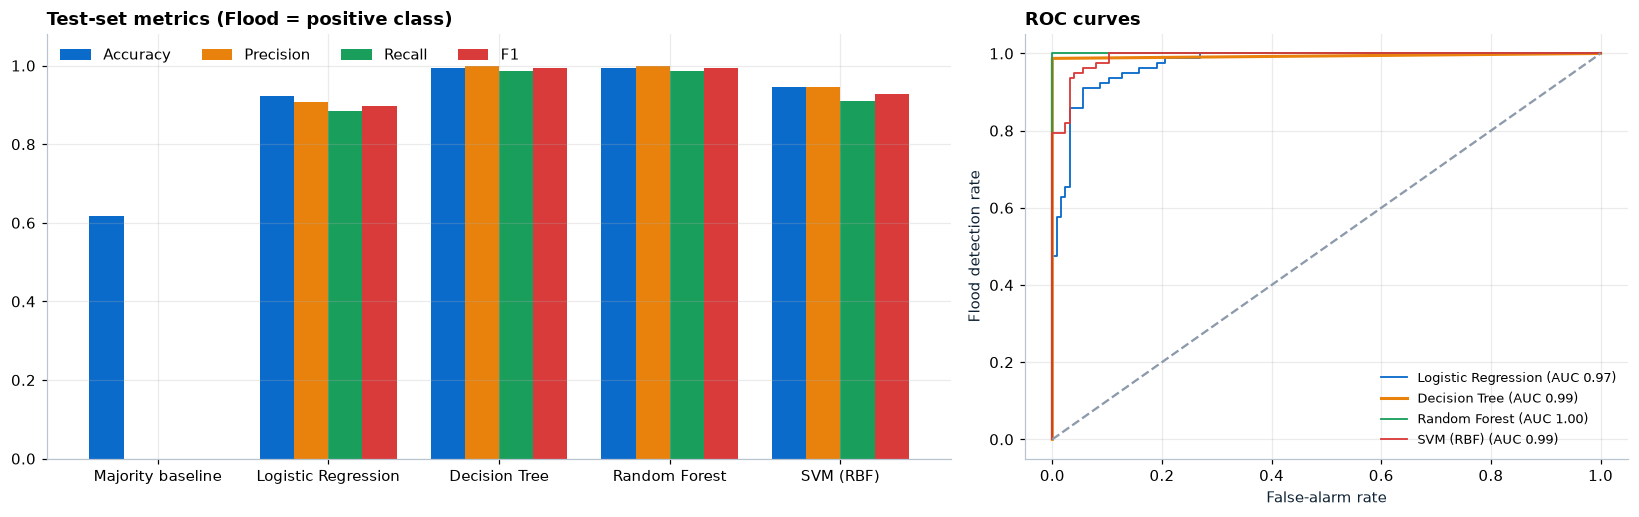

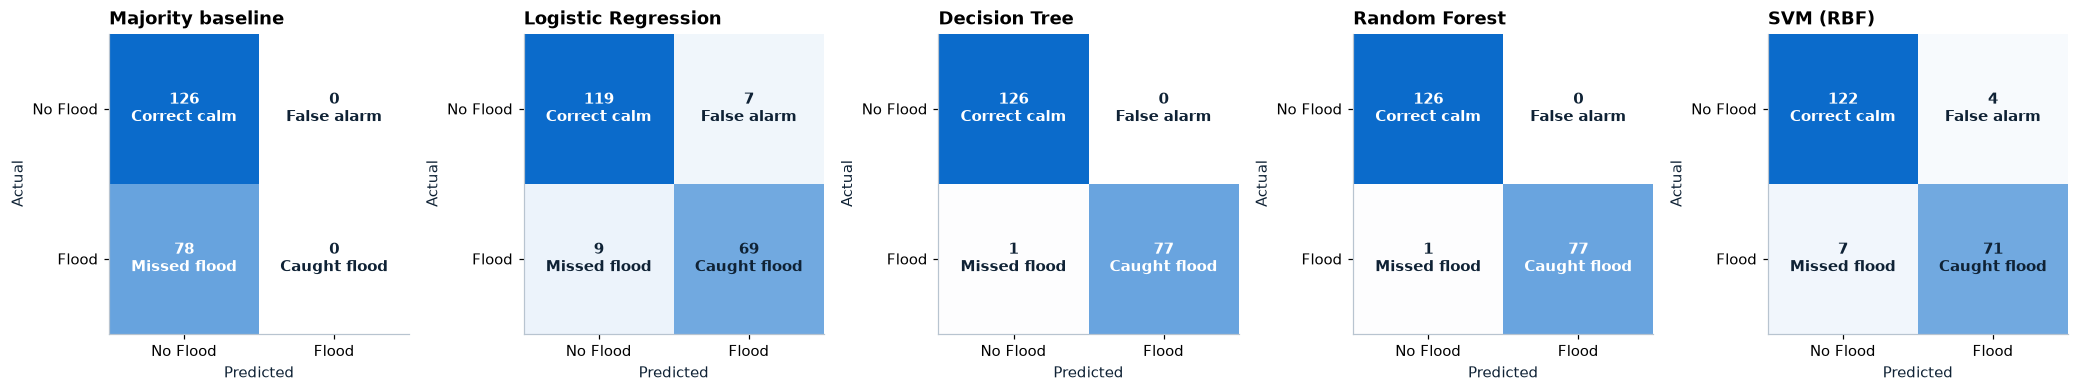

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ml_results.drop(columns=["Validation F1", "ROC-AUC"]).plot(kind="bar", ax=axes[0], width=0.8, ylim=(0, 1.08))
axes[0].tick_params(axis="x", rotation=0); axes[0].set_xlabel(""); axes[0].legend(ncol=4, loc="upper left")
axes[0].set_title("Test-set metrics (Flood = positive class)")
for name, prob in ml_prob.items():
    if name == "Majority baseline":
        continue
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, lw=2 if name == BEST_ML else 1.2, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
axes[1].plot([0, 1], [0, 1], ls="--", color=C["grey"]); axes[1].legend(loc="lower right", fontsize=8.5)
axes[1].set_xlabel("False-alarm rate"); axes[1].set_ylabel("Flood detection rate"); axes[1].set_title("ROC curves")
fig.tight_layout(); save(fig, "task6_model_comparison"); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
for ax, (name, prob) in zip(axes, ml_prob.items()):
    plot_cm(ax, y_test, (prob >= 0.5).astype(int), name)
fig.tight_layout(); save(fig, "task6_confusion_matrices"); plt.show()

### 6.2 Error analysis: what does the best model get wrong?
A **missed flood** (false negative) means people are not warned, the most harmful error. A **false alarm** (false positive) wastes resources and erodes trust.

In [18]:
best_pred = (ml_prob[BEST_ML] >= 0.5).astype(int)
errors = df.iloc[idx_test][["date", "precipitation", "soil_moisture", "water_area_km2", "water_area_change"]].reset_index(drop=True)
errors["Actual"] = np.where(y_test == 1, "Flood", "No Flood")
errors["Flood probability"] = ml_prob[BEST_ML]
errors["Error"] = np.select([(y_test == 1) & (best_pred == 0), (y_test == 0) & (best_pred == 1)],
                            ["Missed flood", "False alarm"], default="")
wrong = errors[errors["Error"] != ""]
print(f"{BEST_ML}: {len(wrong)} mistakes on {len(errors)} unseen days → "
      f"{(wrong['Error'] == 'Missed flood').sum()} missed floods, {(wrong['Error'] == 'False alarm').sum()} false alarms")
display(table(wrong.head(12)).hide(axis="index"))

typical = errors.groupby(["Actual"])[["precipitation", "water_area_change"]].median()
display(Markdown("**Median readings by actual class (test period)**: missed floods usually look like calm days on these readings."))
display(table(typical))

Decision Tree: 1 mistakes on 204 unseen days → 1 missed floods, 0 false alarms


date,precipitation,soil_moisture,water_area_km2,water_area_change,Actual,Flood probability,Error
2025-06-10 00:00:00,0.181,0.103,588.510,-167.510,Flood,0.000,Missed flood


**Median readings by actual class (test period)**: missed floods usually look like calm days on these readings.

,precipitation,water_area_change
Actual,,
Flood,0.117,321.405
No Flood,0.026,-71.883


### 6.3 Sensitivity check: what if the water-area readings are removed?
If performance collapses without them, the models depend on a possible target proxy rather than on rainfall and soil conditions.

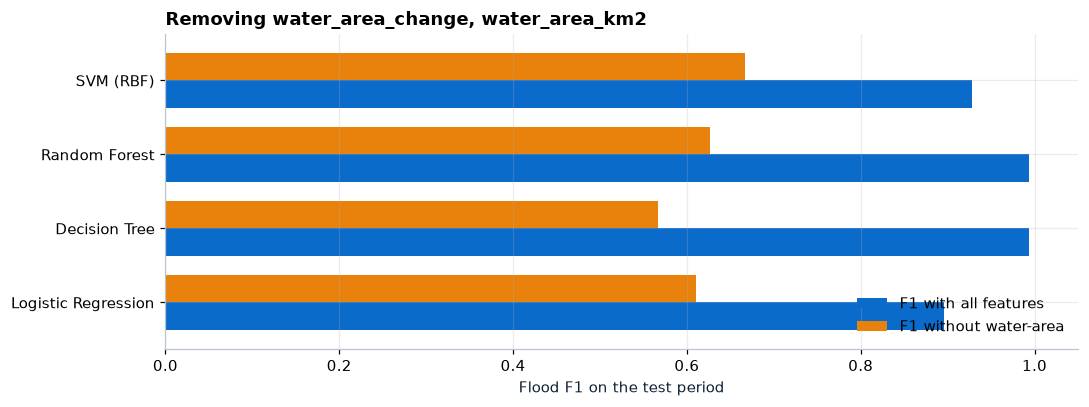

In [19]:
water_cols = [c for c in SELECTED if c.startswith("water_area")]
reduced = [c for c in SELECTED if c not in water_cols]
abl = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest", "SVM (RBF)"]:
    m = ml_models[name].__class__(**ml_models[name].get_params()).fit(X_train[reduced], y_train)
    abl.append({"Model": name, "F1 with all features": ml_results.loc[name, "F1"],
                "F1 without water-area": f1_score(y_test, m.predict(X_test[reduced]), zero_division=0)})
abl = pd.DataFrame(abl).set_index("Model")
fig, ax = plt.subplots(figsize=(10, 3.8))
abl.plot(kind="barh", ax=ax, color=[C["blue"], C["orange"]], width=0.75)
ax.set_xlim(0, 1.05); ax.set_xlabel("Flood F1 on the test period"); ax.set_ylabel("")
ax.set_title(f"Removing {', '.join(water_cols)}"); ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "task6_water_ablation"); plt.show()

### 6.4 SHAP: why does the Random Forest decide what it decides?
**SHAP** (SHapley Additive exPlanations) splits every prediction into contributions from each feature, using game theory. In the **beeswarm** each dot is one test day: its position shows how much that feature pushed the prediction towards *Flood* (right) or *No Flood* (left), and its colour shows whether the feature value was high (red) or low (blue).

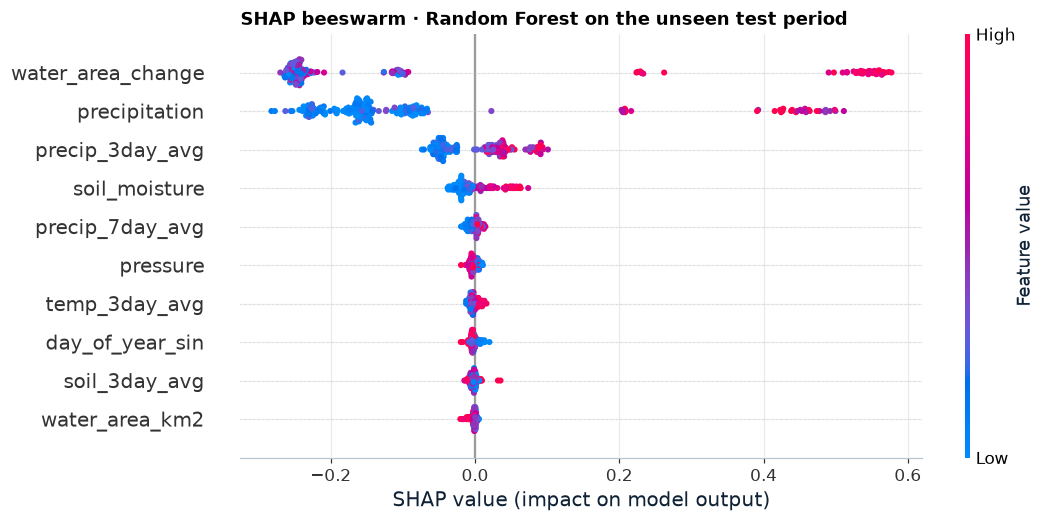

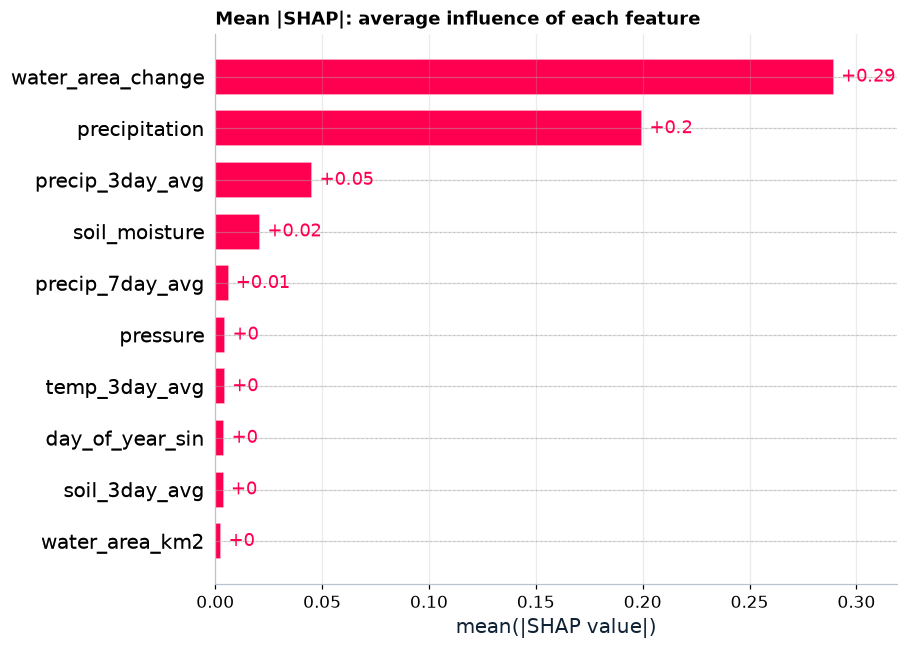

In [20]:
rf_model = ml_models["Random Forest"]
rf_shap = shap.TreeExplainer(rf_model)(X_test)
if rf_shap.values.ndim == 3:                  # (days, features, classes) → keep the Flood class
    rf_shap = rf_shap[:, :, 1]

plt.figure()
shap.plots.beeswarm(rf_shap, max_display=10, show=False, plot_size=(10, 5))
plt.title("SHAP beeswarm · Random Forest on the unseen test period", loc="left", fontweight="bold")
save(plt.gcf(), "task6_shap_beeswarm"); plt.show()

plt.figure()
shap.plots.bar(rf_shap, max_display=10, show=False)
plt.title("Mean |SHAP|: average influence of each feature", loc="left", fontweight="bold")
save(plt.gcf(), "task6_shap_bar"); plt.show()
rf_shap_rank = pd.Series(np.abs(rf_shap.values).mean(0), index=X_test.columns).sort_values(ascending=False)

### 6.5 Unsupervised learning: do natural groups exist?
Ignoring the labels, **K-Means** (partition-based) and **Agglomerative** (hierarchical) clustering group similar days. The silhouette score picks the number of groups; we then check whether any group lines up with floods.

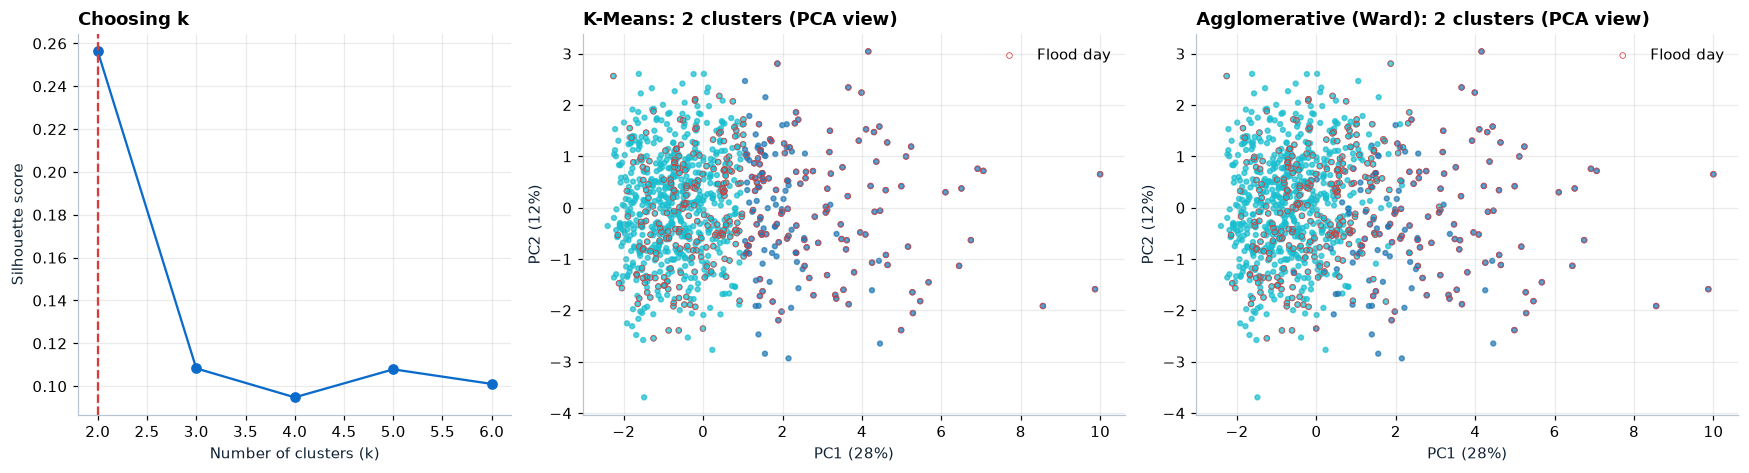

,Days,Flood share
K-Means cluster,,
0,185,0.643
1,765,0.269


Agreement with the real labels (adjusted Rand index): K-Means 0.15, Agglomerative 0.11  (0 = random, 1 = perfect)


> **🔎 Task 6 findings**
>
> - Best model on validation: **Decision Tree**, test F1 0.99, recall 0.99, precision 1.00.
> - Tree models score almost perfectly on the same day's readings (F1 up to 0.99). That is a warning, not a success: the label seems to follow almost directly from that day's water-area change and rainfall.
> - The majority baseline reaches 62% accuracy while catching **zero** floods, which is why accuracy alone is misleading.
> - SHAP shows the Random Forest relies most on **water_area_change** and **precipitation**.
> - Without water-area features, Random-Forest F1 drops from 0.99 to 0.63: the models depend heavily on a possible target proxy.
> - Clusters found without labels (k = 2) do not reproduce the flood label well, so flood days are not a simple natural group.

In [21]:
sil = {k: silhouette_score(X_train, KMeans(k, n_init=10, random_state=SEED).fit_predict(X_train)) for k in range(2, 7)}
K = max(sil, key=sil.get)
km_labels = KMeans(K, n_init=10, random_state=SEED).fit_predict(X_train)
ag_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_train)
pca = PCA(n_components=2, random_state=SEED).fit(X_train)
P = pca.transform(X_train)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [0.8, 1, 1]})
axes[0].plot(list(sil), list(sil.values()), marker="o", color=C["blue"]); axes[0].axvline(K, color=C["red"], ls="--")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Silhouette score"); axes[0].set_title("Choosing k")
for ax, labels, name in [(axes[1], km_labels, "K-Means"), (axes[2], ag_labels, "Agglomerative (Ward)")]:
    sc = ax.scatter(P[:, 0], P[:, 1], c=labels, cmap="tab10", s=10, alpha=0.7)
    ax.scatter(P[y_train == 1, 0], P[y_train == 1, 1], facecolors="none", edgecolors=C["red"], s=14, lw=0.5, label="Flood day")
    ax.set_title(f"{name}: {K} clusters (PCA view)"); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"); ax.legend(loc="upper right")
fig.tight_layout(); save(fig, "task6_clustering"); plt.show()

cluster_table = pd.DataFrame({"K-Means cluster": km_labels, "flood": y_train}).groupby("K-Means cluster")["flood"].agg(["size", "mean"])
cluster_table.columns = ["Days", "Flood share"]
display(table(cluster_table, gradient=["Flood share"]))
print(f"Agreement with the real labels (adjusted Rand index): K-Means {adjusted_rand_score(y_train, km_labels):.2f}, "
      f"Agglomerative {adjusted_rand_score(y_train, ag_labels):.2f}  (0 = random, 1 = perfect)")

best = ml_results.loc[BEST_ML]
findings("Task 6 findings", [
    f"Best model on validation: **{BEST_ML}**, test F1 {best['F1']:.2f}, recall {best['Recall']:.2f}, precision {best['Precision']:.2f}.",
    f"Tree models score almost perfectly on the same day's readings (F1 up to {ml_results['F1'].max():.2f}). "
    "That is a warning, not a success: the label seems to follow almost directly from that day's water-area change and rainfall.",
    f"The majority baseline reaches {ml_results.loc['Majority baseline', 'Accuracy']:.0%} accuracy while catching **zero** floods, "
    "which is why accuracy alone is misleading.",
    f"SHAP shows the Random Forest relies most on **{rf_shap_rank.index[0]}** and **{rf_shap_rank.index[1]}**.",
    f"Without water-area features, Random-Forest F1 drops from {abl.loc['Random Forest', 'F1 with all features']:.2f} to "
    f"{abl.loc['Random Forest', 'F1 without water-area']:.2f}: the models depend heavily on a possible target proxy.",
    f"Clusters found without labels (k = {K}) do not reproduce the flood label well, so flood days are not a simple natural group.",
])

---
## Task 7 · Design, tune and train a deep-learning model (LSTM)
> **Syllabus:** design an advanced deep-learning architecture (CNN, RNN or **LSTM**) suited to the data type; train with appropriate hyperparameters and regularisation. *(LO 3.1)*

The data is a **daily time series**, so an LSTM is the natural choice: it reads the 7 days in order and keeps a memory of what matters. A dense network that sees the same numbers without any notion of order is the baseline.

### 7.1 Build 7-day sequences

LSTM input: (samples, days, features) → train (950, 7, 15) · validation (204, 7, 15) · test (204, 7, 15)


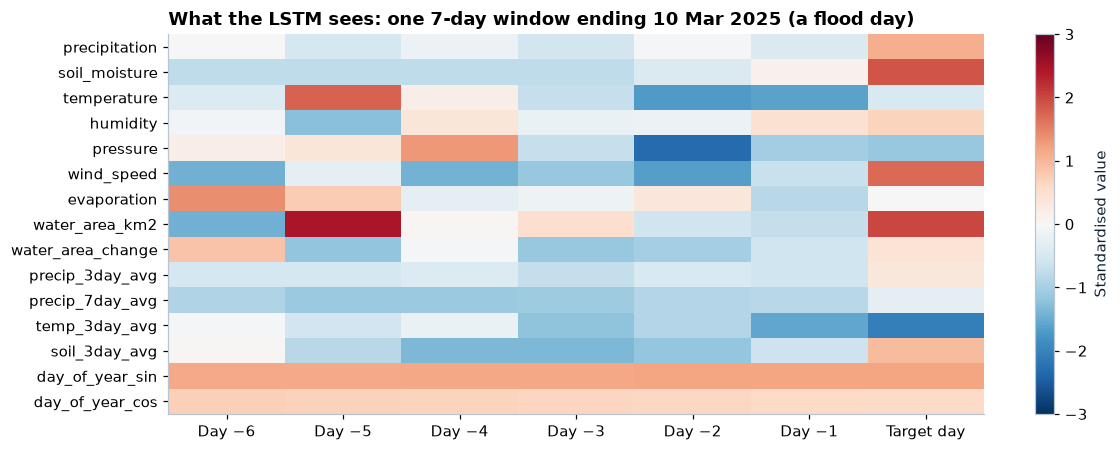

In [22]:
seq_imputer = SimpleImputer(strategy="median")
seq_scaler = StandardScaler()
train_rows = df.iloc[: idx_train[-1] + 1][SEQ_FEATURES]          # fitted on training days only
seq_scaler.fit(seq_imputer.fit_transform(train_rows))
scaled = seq_scaler.transform(seq_imputer.transform(df[SEQ_FEATURES])).astype(np.float32)

def windows(ix):
    return np.stack([scaled[t - WINDOW + 1: t + 1] for t in ix]).astype(np.float32)

S_train, S_val, S_test = windows(idx_train), windows(idx_val), windows(idx_test)
print(f"LSTM input: (samples, days, features) → train {S_train.shape} · validation {S_val.shape} · test {S_test.shape}")

example = int(np.argmax(y_test))
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(S_test[example].T, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(len(SEQ_FEATURES)), SEQ_FEATURES); ax.set_xticks(range(WINDOW), [f"Day −{WINDOW - 1 - d}" if d < WINDOW - 1 else "Target day" for d in range(WINDOW)])
ax.grid(False); fig.colorbar(im, ax=ax, label="Standardised value")
ax.set_title(f"What the LSTM sees: one 7-day window ending {dates_test[example]:%d %b %Y} (a flood day)")
fig.tight_layout(); save(fig, "task7_input_window"); plt.show()

### 7.2 Architectures and training procedure
* **LSTM:** one LSTM layer → last hidden state (a learned summary of the week) → dropout → one output neuron.
* **Dense baseline:** flatten 7 × 15 numbers → hidden layer → dropout → output.
* **Training:** class-weighted binary cross-entropy, the Adam optimiser with weight decay (L2 regularisation), gradient clipping and **early stopping** on validation loss.

In [23]:
class DenseBaseline(nn.Module):
    def __init__(self, n_features, hidden=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(WINDOW * n_features, hidden), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

class FloodLSTM(nn.Module):
    def __init__(self, n_features, hidden=32, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)
    def embed(self, x):
        """Learned 'summary of the week': the LSTM's final hidden state."""
        _, (h, _) = self.lstm(x)
        return h[-1]
    def forward(self, x):
        return self.head(self.dropout(self.embed(x))).squeeze(-1)

POS_WEIGHT = torch.tensor((y_train == 0).sum() / max((y_train == 1).sum(), 1), dtype=torch.float32)

def train_model(model, lr=1e-3, max_epochs=100, patience=10, seed=SEED):
    set_seed(seed)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(torch.from_numpy(S_train), torch.from_numpy(y_train.astype(np.float32))),
                        batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(seed))
    Xv, yv = torch.from_numpy(S_val), torch.from_numpy(y_val.astype(np.float32))
    hist, best, best_state, best_epoch, wait = {"train": [], "val": []}, np.inf, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train(); losses = []
        for xb, yb in loader:
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), yv).item()
        hist["train"].append(np.mean(losses)); hist["val"].append(val_loss)
        if val_loss < best - 1e-4:
            best, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return model, hist, best_epoch

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

### 7.3 Hyperparameter tuning
Four configurations are trained; the LSTM with the best **validation** F1 is selected.

✓ Dense baseline: stopped at epoch 29, best epoch 19, validation F1 0.824


✓ LSTM 16 units · dropout 0.1: stopped at epoch 70, best epoch 60, validation F1 0.895


✓ LSTM 32 units · dropout 0.2: stopped at epoch 36, best epoch 26, validation F1 0.861


✓ LSTM 32 units · dropout 0.3: stopped at epoch 66, best epoch 56, validation F1 0.901


,Learning rate,Best epoch,Validation loss,Validation F1,Validation ROC-AUC
Model,,,,,
Dense baseline,1e-03,19,0.396,0.824,0.947
LSTM 16 units · dropout 0.1,1e-03,60,0.270,0.895,0.975
LSTM 32 units · dropout 0.2,1e-03,26,0.298,0.861,0.968
LSTM 32 units · dropout 0.3,5e-04,56,0.291,0.901,0.969


Selected: LSTM 32 units · dropout 0.3


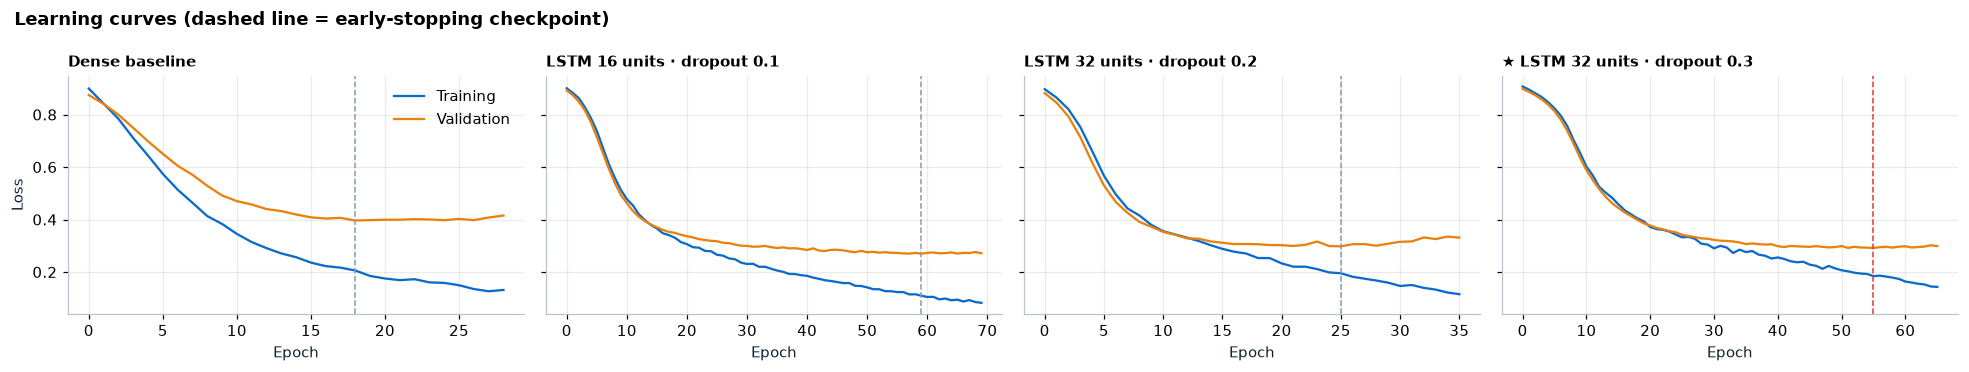

In [24]:
candidates = [
    ("Dense baseline", DenseBaseline, dict(hidden=32, dropout=0.2), 1e-3),
    ("LSTM 16 units · dropout 0.1", FloodLSTM, dict(hidden=16, dropout=0.1), 1e-3),
    ("LSTM 32 units · dropout 0.2", FloodLSTM, dict(hidden=32, dropout=0.2), 1e-3),
    ("LSTM 32 units · dropout 0.3", FloodLSTM, dict(hidden=32, dropout=0.3), 5e-4),
]
dl_models, histories, rows = {}, {}, []
for i, (name, cls, params, lr) in enumerate(candidates):
    set_seed(SEED + i)
    model, hist, best_epoch = train_model(cls(len(SEQ_FEATURES), **params), lr=lr, seed=SEED + i)
    dl_models[name], histories[name] = model, (hist, best_epoch)
    val_s = scores(y_val, predict(model, S_val))
    rows.append({"Model": name, "Learning rate": lr, "Best epoch": best_epoch,
                 "Validation loss": min(hist["val"]), "Validation F1": val_s["F1"], "Validation ROC-AUC": val_s["ROC-AUC"]})
    print(f"✓ {name}: stopped at epoch {len(hist['val'])}, best epoch {best_epoch}, validation F1 {val_s['F1']:.3f}")
tuning = pd.DataFrame(rows).set_index("Model")
BEST_LSTM = tuning.drop("Dense baseline")["Validation F1"].idxmax()
lstm, dense = dl_models[BEST_LSTM], dl_models["Dense baseline"]
display(table(tuning, gradient=["Validation F1"], formats={"Learning rate": "{:.0e}"}))
print(f"Selected: {BEST_LSTM}")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.4), sharey=True)
for ax, (name, (hist, be)) in zip(axes, histories.items()):
    ax.plot(hist["train"], label="Training", color=C["blue"]); ax.plot(hist["val"], label="Validation", color=C["orange"])
    ax.axvline(be - 1, color=C["red"] if name == BEST_LSTM else C["grey"], ls="--", lw=1)
    ax.set_title(("★ " if name == BEST_LSTM else "") + name, fontsize=10); ax.set_xlabel("Epoch")
axes[0].set_ylabel("Loss"); axes[0].legend()
fig.suptitle("Learning curves (dashed line = early-stopping checkpoint)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "task7_learning_curves"); plt.show()

### 7.4 Final test: LSTM vs dense baseline on the unseen period

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dense baseline,0.907,0.915,0.833,0.872,0.970
LSTM 32 units · dropout 0.3,0.907,0.873,0.885,0.879,0.973


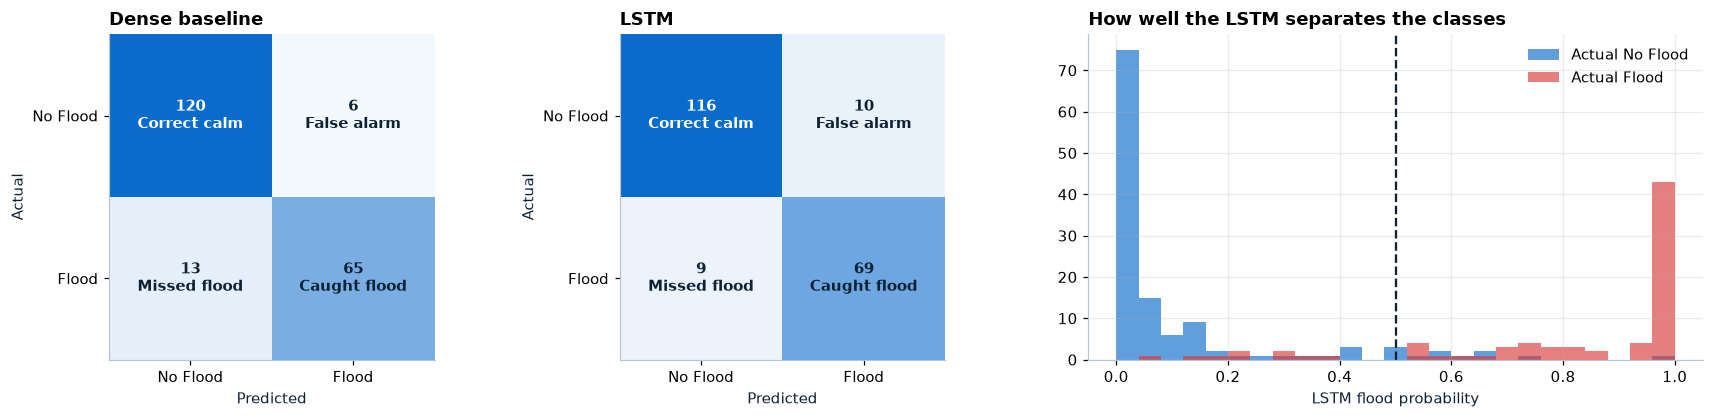

> **🔎 Task 7 findings**
>
> - Selected **LSTM 32 units · dropout 0.3** on validation data; test F1 0.88 vs dense baseline 0.87, ROC-AUC 0.97.
> - Regularisation used: dropout, L2 weight decay, gradient clipping and early stopping. Every curve stops before validation loss rises.
> - Most test days get a confident probability near 0 or 1; the overlap in the middle is where mistakes happen.

In [25]:
p_dense, p_lstm = predict(dense, S_test), predict(lstm, S_test)
dl_results = pd.DataFrame([{"Model": "Dense baseline", **scores(y_test, p_dense)},
                           {"Model": BEST_LSTM, **scores(y_test, p_lstm)}]).set_index("Model")
display(table(dl_results, gradient=["F1", "Recall"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.5]})
plot_cm(axes[0], y_test, (p_dense >= 0.5).astype(int), "Dense baseline")
plot_cm(axes[1], y_test, (p_lstm >= 0.5).astype(int), "LSTM")
bins = np.linspace(0, 1, 26)
axes[2].hist(p_lstm[y_test == 0], bins=bins, alpha=0.65, color=C["blue"], label="Actual No Flood")
axes[2].hist(p_lstm[y_test == 1], bins=bins, alpha=0.65, color=C["red"], label="Actual Flood")
axes[2].axvline(0.5, color=C["ink"], ls="--"); axes[2].legend(); axes[2].set_xlabel("LSTM flood probability")
axes[2].set_title("How well the LSTM separates the classes")
fig.tight_layout(); save(fig, "task7_test_results"); plt.show()

findings("Task 7 findings", [
    f"Selected **{BEST_LSTM}** on validation data; test F1 {dl_results.loc[BEST_LSTM, 'F1']:.2f} vs dense baseline "
    f"{dl_results.loc['Dense baseline', 'F1']:.2f}, ROC-AUC {dl_results.loc[BEST_LSTM, 'ROC-AUC']:.2f}.",
    "Regularisation used: dropout, L2 weight decay, gradient clipping and early stopping. Every curve stops before validation loss rises.",
    "Most test days get a confident probability near 0 or 1; the overlap in the middle is where mistakes happen.",
])

---
## Task 8 · Interpret the deep-learning model
> **Syllabus:** apply interpretability and visualisation methods (feature maps, activation visualisation, attention); compare performance and interpretability with the basic model. *(LO 3.2)*

Four complementary lenses: **which readings** matter (permutation), **which days** matter (time-step ablation), **what happens inside** the LSTM (activations) and a per-prediction breakdown (**SHAP**).

### 8.1 Feature permutation: which readings does each model rely on?
One reading's full 7-day history is shuffled between test days. If ROC-AUC drops sharply, the model relied on that reading.

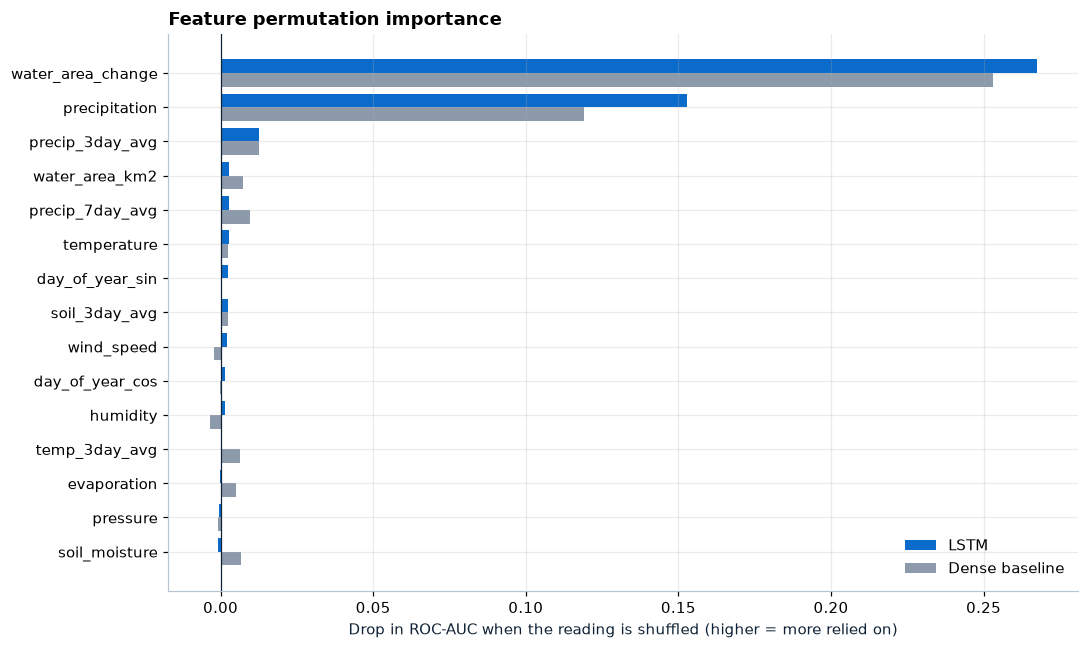

In [26]:
rng = np.random.default_rng(SEED)
perm_rows = []
for model_name, model in [("Dense baseline", dense), ("LSTM", lstm)]:
    base_auc = roc_auc_score(y_test, predict(model, S_test))
    for j, feature in enumerate(SEQ_FEATURES):
        drops = []
        for _ in range(5):
            Xp = S_test.copy(); Xp[:, :, j] = S_test[rng.permutation(len(S_test)), :, j]
            drops.append(base_auc - roc_auc_score(y_test, predict(model, Xp)))
        perm_rows.append({"Model": model_name, "Feature": feature, "AUC drop": np.mean(drops)})
perm = pd.DataFrame(perm_rows).pivot(index="Feature", columns="Model", values="AUC drop").sort_values("LSTM")

fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(perm))
ax.barh(ypos + 0.2, perm["LSTM"], height=0.4, color=C["blue"], label="LSTM")
ax.barh(ypos - 0.2, perm["Dense baseline"], height=0.4, color=C["grey"], label="Dense baseline")
ax.set_yticks(ypos, perm.index); ax.axvline(0, color=C["ink"], lw=0.8); ax.legend(loc="lower right")
ax.set_xlabel("Drop in ROC-AUC when the reading is shuffled (higher = more relied on)")
ax.set_title("Feature permutation importance")
fig.tight_layout(); save(fig, "task8_permutation"); plt.show()

### 8.2 Time-step ablation: which of the 7 days matters?
One day at a time is replaced by the training average (0 after scaling), and we measure how much the predicted probability moves.

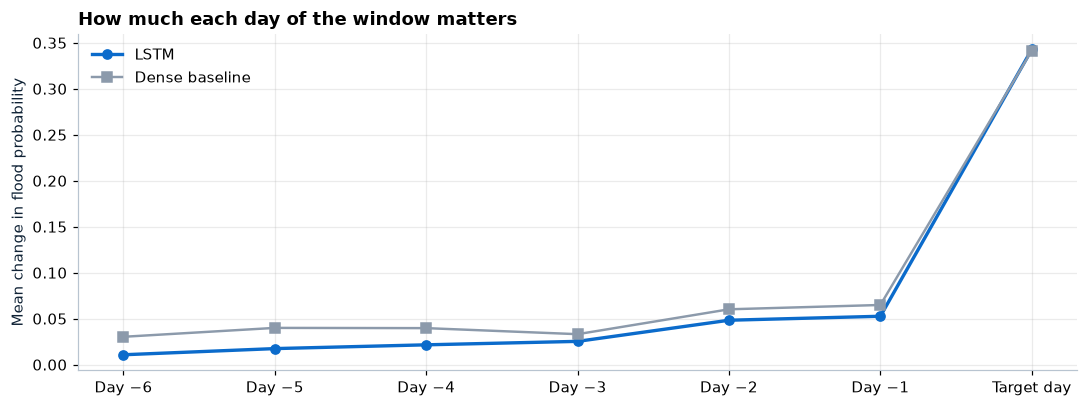

In [27]:
day_labels = [f"Day −{WINDOW - 1 - d}" for d in range(WINDOW - 1)] + ["Target day"]
time_rows = []
for model_name, model in [("Dense baseline", dense), ("LSTM", lstm)]:
    base = predict(model, S_test)
    for d in range(WINDOW):
        Xa = S_test.copy(); Xa[:, d, :] = 0.0
        time_rows.append({"Model": model_name, "Day": day_labels[d], "Mean |Δ probability|": np.abs(predict(model, Xa) - base).mean()})
time_imp = pd.DataFrame(time_rows).pivot(index="Day", columns="Model", values="Mean |Δ probability|").reindex(day_labels)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(day_labels, time_imp["LSTM"], marker="o", lw=2.2, color=C["blue"], label="LSTM")
ax.plot(day_labels, time_imp["Dense baseline"], marker="s", lw=1.6, color=C["grey"], label="Dense baseline")
ax.set_ylabel("Mean change in flood probability"); ax.legend(); ax.set_title("How much each day of the window matters")
fig.tight_layout(); save(fig, "task8_time_steps"); plt.show()

### 8.3 Activation visualisation: inside the LSTM
The LSTM's hidden units after each day, averaged separately over flood and normal test days. The third panel shows the **difference**: units that light up differently for floods are the ones carrying the flood signal.

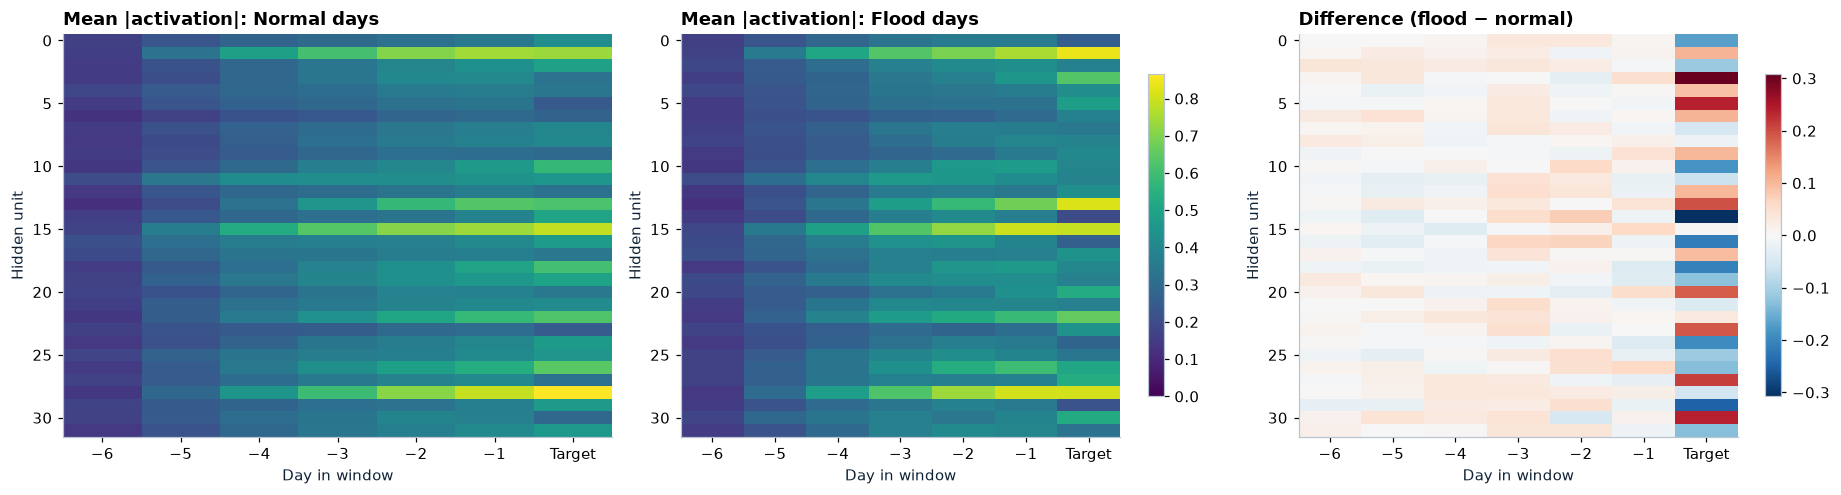

In [28]:
with torch.no_grad():
    acts = lstm.lstm(torch.from_numpy(S_test))[0].numpy()            # (days, time steps, hidden units)
act_flood, act_calm = np.abs(acts[y_test == 1]).mean(0), np.abs(acts[y_test == 0]).mean(0)
diff = act_flood - act_calm

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
vmax = max(act_flood.max(), act_calm.max())
for ax, data, title in [(axes[0], act_calm, "Normal days"), (axes[1], act_flood, "Flood days")]:
    im = ax.imshow(data.T, aspect="auto", cmap="viridis", vmin=0, vmax=vmax); ax.set_title(f"Mean |activation|: {title}")
im2 = axes[2].imshow(diff.T, aspect="auto", cmap="RdBu_r", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[2].set_title("Difference (flood − normal)")
for ax in axes:
    ax.set_xticks(range(WINDOW), ["−6", "−5", "−4", "−3", "−2", "−1", "Target"]); ax.set_xlabel("Day in window")
    ax.set_ylabel("Hidden unit"); ax.grid(False)
fig.colorbar(im, ax=axes[1], shrink=0.8); fig.colorbar(im2, ax=axes[2], shrink=0.8)
fig.tight_layout(); save(fig, "task8_activations"); plt.show()

### 8.4 SHAP for the LSTM
`GradientExplainer` (expected gradients) gives a SHAP value for **every reading on every day**. Summing over the 7 days gives one value per reading, shown as a beeswarm. Colour = the reading's value on the target day.

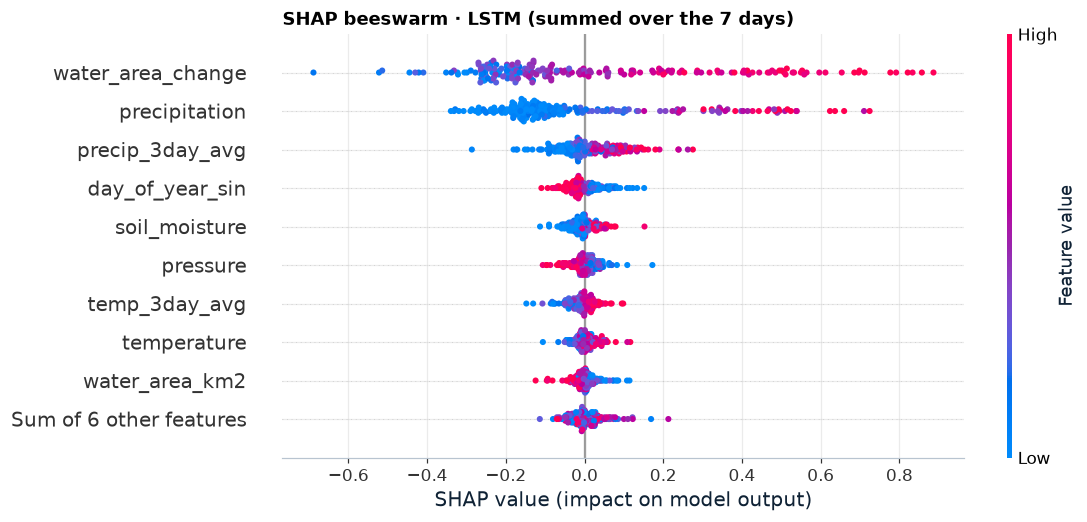

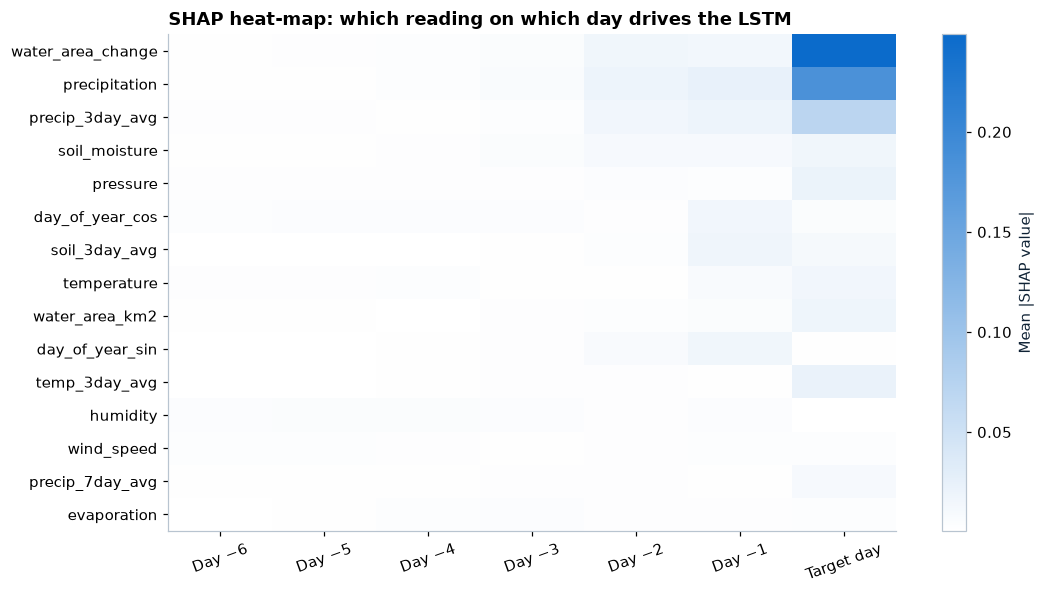

In [29]:
class ProbabilityOutput(nn.Module):
    """Wraps the LSTM so SHAP explains the flood probability directly."""
    def __init__(self, model):
        super().__init__(); self.model = model
    def forward(self, x):
        return torch.sigmoid(self.model(x)).unsqueeze(-1)

background = torch.from_numpy(S_train[np.random.default_rng(SEED).choice(len(S_train), 100, replace=False)])
explainer = shap.GradientExplainer(ProbabilityOutput(lstm).eval(), background)
lstm_shap = explainer.shap_values(torch.from_numpy(S_test))
lstm_shap = np.asarray(lstm_shap[0] if isinstance(lstm_shap, list) else lstm_shap)
if lstm_shap.ndim == 4:
    lstm_shap = lstm_shap[..., 0]                                     # (days, 7 time steps, 15 features)
SHAP_BASE = float(predict(lstm, background.numpy()).mean())

per_feature = shap.Explanation(values=lstm_shap.sum(1), data=S_test[:, -1, :], feature_names=SEQ_FEATURES)
plt.figure()
shap.plots.beeswarm(per_feature, max_display=10, show=False, plot_size=(10, 5))
plt.title("SHAP beeswarm · LSTM (summed over the 7 days)", loc="left", fontweight="bold")
save(plt.gcf(), "task8_shap_beeswarm"); plt.show()

heat = np.abs(lstm_shap).mean(0).T                                   # features × days
order = np.argsort(heat.sum(1))[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(heat[order], cmap=CM_CMAP, aspect="auto")
ax.set_yticks(range(len(order)), [SEQ_FEATURES[i] for i in order]); ax.set_xticks(range(WINDOW), day_labels, rotation=20)
ax.grid(False); fig.colorbar(im, ax=ax, label="Mean |SHAP value|")
ax.set_title("SHAP heat-map: which reading on which day drives the LSTM")
fig.tight_layout(); save(fig, "task8_shap_heatmap"); plt.show()

### 8.5 Comparison: basic model vs LSTM

In [30]:
lstm_shap_rank = pd.Series(np.abs(lstm_shap).sum(1).mean(0), index=SEQ_FEATURES).sort_values(ascending=False)
comparison = pd.DataFrame({
    "Dense baseline": [f"{dl_results.loc['Dense baseline', 'F1']:.3f}", f"{dl_results.loc['Dense baseline', 'ROC-AUC']:.3f}",
                       ", ".join(perm["Dense baseline"].sort_values(ascending=False).index[:3]),
                       time_imp["Dense baseline"].idxmax(), "No: sees a flat list of 105 numbers"],
    "LSTM": [f"{dl_results.loc[BEST_LSTM, 'F1']:.3f}", f"{dl_results.loc[BEST_LSTM, 'ROC-AUC']:.3f}",
             ", ".join(perm["LSTM"].sort_values(ascending=False).index[:3]),
             time_imp["LSTM"].idxmax(), "Yes: hidden state evolves day by day (8.3)"],
}, index=["Test F1", "Test ROC-AUC", "Top-3 readings (permutation)", "Most influential day", "Models the order of days?"])
display(comparison)

findings("Task 8 findings", [
    f"Permutation and SHAP agree: the LSTM depends most on **{lstm_shap_rank.index[0]}** and **{lstm_shap_rank.index[1]}**, "
    "the same water-area signal the classical models used, so the proxy concern applies to deep learning too.",
    f"The **{time_imp['LSTM'].idxmax()}** influences the LSTM most; earlier days add context but matter less.",
    "Activation maps show specific hidden units responding differently to flood weeks, especially on the last days.",
    "All four methods measure what the model *uses*, not what *causes* floods.",
])

,Dense baseline,LSTM
Test F1,0.872,0.879
Test ROC-AUC,0.970,0.973
Top-3 readings (permutation),"water_area_change, precipitation, precip_3day_avg","water_area_change, precipitation, precip_3day_avg"
Most influential day,Target day,Target day
Models the order of days?,No: sees a flat list of 105 numbers,Yes: hidden state evolves day by day (8.3)


> **🔎 Task 8 findings**
>
> - Permutation and SHAP agree: the LSTM depends most on **water_area_change** and **precipitation**, the same water-area signal the classical models used, so the proxy concern applies to deep learning too.
> - The **Target day** influences the LSTM most; earlier days add context but matter less.
> - Activation maps show specific hidden units responding differently to flood weeks, especially on the last days.
> - All four methods measure what the model *uses*, not what *causes* floods.

---
## Task 9 · Integrate DL, ML and AI reasoning into one system
> **Syllabus:** design and implement an end-to-end pipeline integrating **Deep Learning** (feature representation), **Machine Learning** (prediction) and **Artificial Intelligence** (decision making); test with representative inputs. *(LO 4.1)*

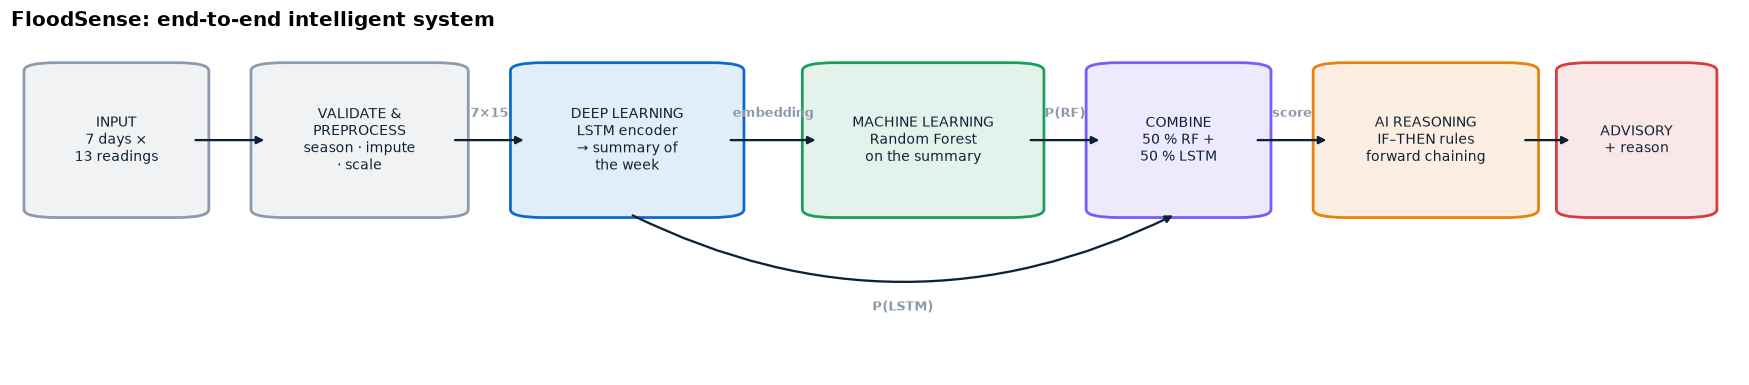

In [31]:
#@title 🧭 System architecture diagram
def draw_flow(ax, boxes, arrows, title):
    for key, (x, y, w, h, text, color) in boxes.items():
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.012,rounding_size=0.02",
                                    fc=color + "1F", ec=color, lw=1.8))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.2, color=C["ink"])
    for a, b, label, style in arrows:
        xa, ya, wa, ha, *_ = boxes[a]; xb, yb, wb, hb, *_ = boxes[b]
        start, end = (xa + wa, ya + ha / 2), (xb, yb + hb / 2)
        if style == "below":
            start, end = (xa + wa / 2, ya), (xb + wb / 2, yb)
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", lw=1.5, color=C["ink"],
                    shrinkA=4, shrinkB=4, connectionstyle="arc3,rad=0.25" if style == "below" else "arc3"))
        if label:
            mx = (start[0] + end[0]) / 2
            my = min(ya, yb) - 0.25 if style == "below" else start[1] + 0.05
            ax.text(mx, my, label, ha="center", va="bottom", fontsize=8.5, color=C["grey"], fontweight="bold")
    tops = [y + h for _, y, _, h, *_ in boxes.values()]
    bottoms = [y for _, y, *_ in boxes.values()]
    has_below = any(style == "below" for *_, style in arrows)
    ax.set_xlim(-0.02, 1.045); ax.set_ylim(min(bottoms) - (0.40 if has_below else 0.08), max(tops) + 0.08)
    ax.axis("off"); ax.set_title(title, fontsize=13)

fig, ax = plt.subplots(figsize=(16, 3.6))
boxes = {   # x, y, width, height, text, colour (gaps leave room for the arrow labels)
    "in":  (0.00, 0.50, 0.090, 0.36, "INPUT\n7 days ×\n13 readings", C["grey"]),
    "pre": (0.140, 0.50, 0.110, 0.36, "VALIDATE &\nPREPROCESS\nseason · impute\n· scale", C["grey"]),
    "dl":  (0.300, 0.50, 0.120, 0.36, "DEEP LEARNING\nLSTM encoder\n→ summary of\nthe week", C["blue"]),
    "ml":  (0.480, 0.50, 0.125, 0.36, "MACHINE LEARNING\nRandom Forest\non the summary", C["green"]),
    "mix": (0.655, 0.50, 0.090, 0.36, "COMBINE\n50 % RF +\n50 % LSTM", C["purple"]),
    "ai":  (0.795, 0.50, 0.115, 0.36, "AI REASONING\nIF–THEN rules\nforward chaining", C["orange"]),
    "out": (0.945, 0.50, 0.075, 0.36, "ADVISORY\n+ reason", C["red"]),
}
arrows = [("in", "pre", "", ""), ("pre", "dl", "7×15", ""), ("dl", "ml", "embedding", ""),
          ("ml", "mix", "P(RF)", ""), ("dl", "mix", "P(LSTM)", "below"), ("mix", "ai", "score", ""), ("ai", "out", "", "")]
draw_flow(ax, boxes, arrows, "FloodSense: end-to-end intelligent system")
fig.tight_layout(); save(fig, "task9_architecture"); plt.show()

### 9.1 DL → ML: the LSTM's learned summary feeds a Random Forest
The tuned LSTM from Task 7 is reused as a **feature extractor**: its final hidden state is a compact, learned representation of the whole week. A Random Forest trained on those representations gives a second, independent probability.

In [32]:
def embed(X):
    with torch.no_grad():
        return lstm.embed(torch.from_numpy(X)).numpy()

E_train, E_val, E_test = embed(S_train), embed(S_val), embed(S_test)
rf_on_lstm = RandomForestClassifier(n_estimators=250, max_depth=6, min_samples_leaf=3,
                                    class_weight="balanced", random_state=SEED, n_jobs=-1).fit(E_train, y_train)
p_dl = {s: predict(lstm, X) for s, X in [("val", S_val), ("test", S_test)]}
p_ml = {s: rf_on_lstm.predict_proba(E)[:, 1] for s, E in [("val", E_val), ("test", E_test)]}
p_sys = {s: 0.5 * p_dl[s] + 0.5 * p_ml[s] for s in ["val", "test"]}
print(f"Embedding size per window: {E_train.shape[1]} numbers · Random Forest: {rf_on_lstm.n_estimators} trees")

Embedding size per window: 32 numbers · Random Forest: 250 trees


### 9.2 Choose decision thresholds on validation data
Each score needs a "flood line". We pick the threshold with the best **validation** F1. The test set is still untouched.

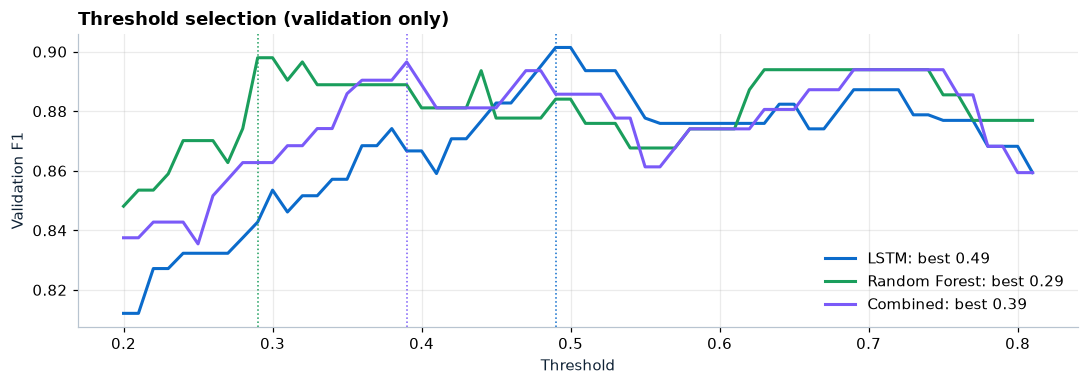

In [33]:
grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
def best_threshold(prob):
    f1s = [f1_score(y_val, (prob >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))]), f1s

TH = {}
fig, ax = plt.subplots(figsize=(10, 3.6))
for key, label, color in [("dl", "LSTM", C["blue"]), ("ml", "Random Forest", C["green"]), ("sys", "Combined", C["purple"])]:
    prob = {"dl": p_dl, "ml": p_ml, "sys": p_sys}[key]["val"]
    TH[key], curve = best_threshold(prob)
    ax.plot(grid, curve, color=color, lw=2, label=f"{label}: best {TH[key]:.2f}")
    ax.axvline(TH[key], color=color, ls=":", lw=1)
ax.set_xlabel("Threshold"); ax.set_ylabel("Validation F1"); ax.legend(); ax.set_title("Threshold selection (validation only)")
fig.tight_layout(); save(fig, "task9_thresholds"); plt.show()

### 9.3 AI reasoning: a transparent rule engine (forward chaining)
Facts are gathered (model verdicts and environmental triggers), then rules are checked **from most to least severe**; the first rule that fires gives the advisory. Environmental trigger levels are the **90th percentile of the training period**, so they mean "unusual for this place".

In [34]:
train_period = df.iloc[: idx_train[-1] + 1]
RULE_LEVELS = {
    "heavy_rain": float(train_period["precipitation"].quantile(0.90)),
    "wet_soil": float(train_period["soil_moisture"].quantile(0.90)),
    "rapid_rise": float(train_period.loc[train_period["water_area_change"] > 0, "water_area_change"].quantile(0.90)),
}
WATCH_LEVEL = max(0.35, TH["sys"])

RULES = [  # (id, advisory, plain-language condition, test on facts)
    ("R1", "FLOOD WARNING", "Both models say Flood, or combined score ≥ 75 %",
     lambda f: (f["dl_flood"] and f["ml_flood"]) or f["score"] >= 0.75),
    ("R2", "FLOOD WATCH", f"Combined score ≥ {WATCH_LEVEL:.0%}, or rapid water rise with heavy rain / wet soil",
     lambda f: f["score"] >= WATCH_LEVEL or (f["rapid_rise"] and (f["heavy_rain"] or f["wet_soil"]))),
    ("R3", "MONITOR", "Any environmental trigger is active",
     lambda f: f["heavy_rain"] or f["wet_soil"] or f["rapid_rise"]),
    ("R4", "LOW RISK", "No rule above fired", lambda f: True),
]

def gather_facts(last_day, pdl, pml):
    return {"dl_flood": pdl >= TH["dl"], "ml_flood": pml >= TH["ml"], "score": 0.5 * pdl + 0.5 * pml,
            "heavy_rain": last_day["precipitation"] >= RULE_LEVELS["heavy_rain"],
            "wet_soil": last_day["soil_moisture"] >= RULE_LEVELS["wet_soil"],
            "rapid_rise": last_day["water_area_change"] >= RULE_LEVELS["rapid_rise"]}

def forward_chain(facts):
    for rule_id, advisory, text, test in RULES:
        if test(facts):
            return advisory, rule_id, text

display(pd.DataFrame([(r, a, t) for r, a, t, _ in RULES], columns=["Rule", "Advisory", "Fires when…"]).style.hide(axis="index"))
display(pd.DataFrame({"Trigger level (training 90th percentile)": RULE_LEVELS}).style.format(precision=4))

Rule,Advisory,Fires when…
R1,FLOOD WARNING,"Both models say Flood, or combined score ≥ 75 %"
R2,FLOOD WATCH,"Combined score ≥ 39%, or rapid water rise with heavy rain / wet soil"
R3,MONITOR,Any environmental trigger is active
R4,LOW RISK,No rule above fired


,Trigger level (training 90th percentile)
heavy_rain,0.2628
wet_soil,0.1088
rapid_rise,482.7110


### 9.4 The integrated system as one reusable component
`FloodSenseSystem` joins every part: **validate → preprocess → LSTM → Random Forest → combine → rules**. It accepts a raw 7-day table, exactly what a user or a website would send.

In [35]:
class FloodSenseSystem:
    def __init__(self):
        self.encoder, self.rf, self.imputer, self.scaler = lstm, rf_on_lstm, seq_imputer, seq_scaler

    def validate_window(self, window):
        if not isinstance(window, pd.DataFrame):
            raise TypeError("Input must be a table (pandas DataFrame).")
        missing = [c for c in ["date"] + ENV if c not in window.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        if len(window) != WINDOW:
            raise ValueError(f"Exactly {WINDOW} daily rows are required, got {len(window)}.")
        w = window.copy()
        w["date"] = pd.to_datetime(w["date"], errors="coerce")
        if w["date"].isna().any():
            raise ValueError("Invalid date found; use YYYY-MM-DD.")
        if w["date"].duplicated().any():
            raise ValueError("Duplicate dates found.")
        w = w.sort_values("date").reset_index(drop=True)
        if not w["date"].diff().dropna().dt.days.eq(1).all():
            raise ValueError("Dates must be consecutive days.")
        w[ENV] = w[ENV].apply(pd.to_numeric, errors="coerce")
        if w[ENV].isna().all().any():
            raise ValueError(f"Columns with no numeric values: {w[ENV].columns[w[ENV].isna().all()].tolist()}")
        return w

    def predict_window(self, window):
        w = self.validate_window(window)
        d = w["date"].dt.dayofyear
        w["day_of_year_sin"], w["day_of_year_cos"] = np.sin(2 * np.pi * d / 365.25), np.cos(2 * np.pi * d / 365.25)
        x = self.scaler.transform(self.imputer.transform(w[SEQ_FEATURES])).astype(np.float32)[None]
        with torch.no_grad():
            t = torch.from_numpy(x)
            pdl = float(torch.sigmoid(self.encoder(t))[0]); emb = self.encoder.embed(t).numpy()
        pml = float(self.rf.predict_proba(emb)[0, 1])
        facts = gather_facts(w.iloc[-1], pdl, pml)
        advisory, rule_id, rule_text = forward_chain(facts)
        return {"date": w["date"].iloc[-1].date(), "P(LSTM)": pdl, "P(RF)": pml, "Combined": facts["score"],
                "Prediction": "Flood" if facts["score"] >= TH["sys"] else "No Flood",
                "Advisory": advisory, "Rule": rule_id, "Why": rule_text,
                "Triggers": [k for k in ["heavy_rain", "wet_soil", "rapid_rise"] if facts[k]]}

system = FloodSenseSystem()
def window_ending(i):
    return df.iloc[i - WINDOW + 1: i + 1][["date"] + ENV]

results = pd.DataFrame([system.predict_window(window_ending(i)) for i in idx_test])
results["Actual"] = np.where(y_test == 1, "Flood", "No Flood")
assert np.allclose(results["Combined"], p_sys["test"], atol=1e-5), "Class output must match the batch pipeline"
print(f"Ran the full system on {len(results)} unseen windows ✓ (matches the batch pipeline)")
display(results.head(8).round(3))

Ran the full system on 204 unseen windows ✓ (matches the batch pipeline)


,date,P(LSTM),P(RF),Combined,Prediction,Advisory,Rule,Why,Triggers,Actual
0,2025-03-06,0.145,0.087,0.116,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
1,2025-03-07,0.002,0.000,0.001,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
2,2025-03-08,0.013,0.003,0.008,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
3,2025-03-09,0.003,0.000,0.002,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
4,2025-03-10,0.963,0.898,0.931,Flood,FLOOD WARNING,R1,"Both models say Flood, or combined score ≥ 75 %",[wet_soil],Flood
5,2025-03-11,0.003,0.000,0.002,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
6,2025-03-12,0.001,0.000,0.001,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
7,2025-03-13,0.027,0.009,0.018,No Flood,LOW RISK,R4,No rule above fired,[],No Flood


### 9.5 Component vs end-to-end performance

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Component,,,,,,
LSTM alone (DL),0.490,0.902,0.863,0.885,0.873,0.973
Random Forest on LSTM summary (DL→ML),0.290,0.902,0.837,0.923,0.878,0.973
Integrated score (DL+ML),0.390,0.897,0.843,0.897,0.870,0.973
Advisory = Watch or Warning (DL+ML+AI),nan,0.897,0.843,0.897,0.870,nan


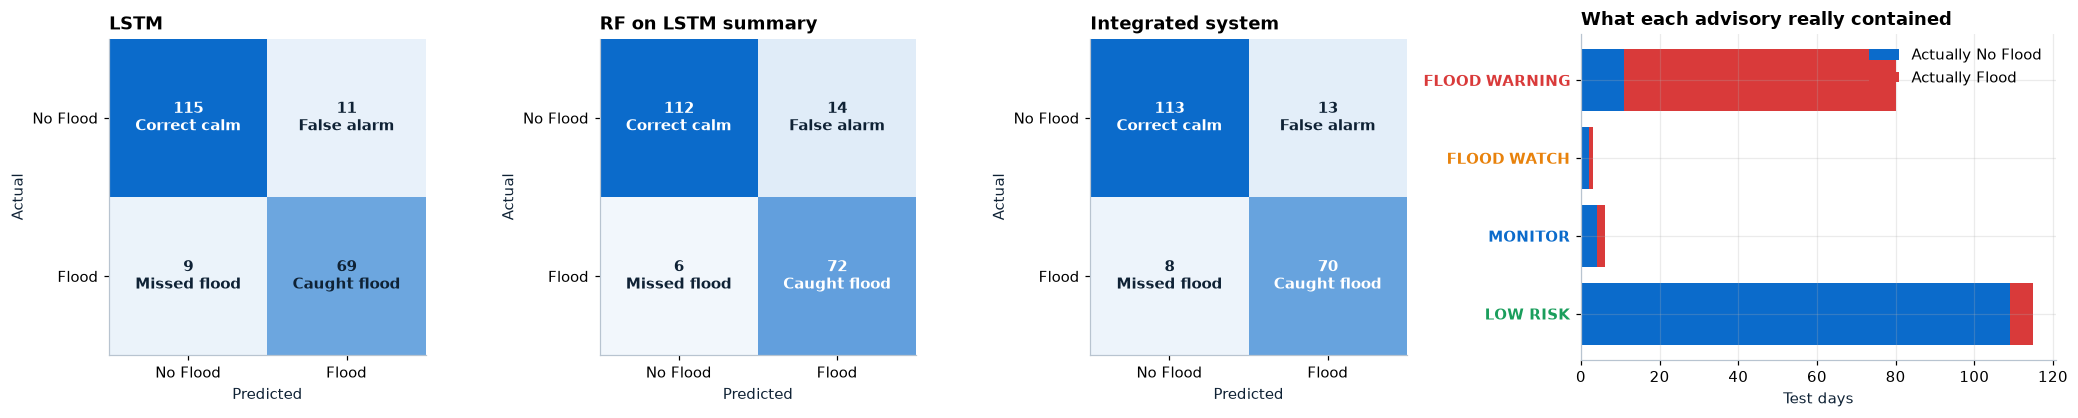

In [36]:
y_sys = (results["Prediction"] == "Flood").astype(int).to_numpy()
alert = results["Advisory"].isin(["FLOOD WATCH", "FLOOD WARNING"]).astype(int).to_numpy()
components = pd.DataFrame([
    {"Component": "LSTM alone (DL)", "Threshold": TH["dl"], **scores(y_test, p_dl["test"], TH["dl"])},
    {"Component": "Random Forest on LSTM summary (DL→ML)", "Threshold": TH["ml"], **scores(y_test, p_ml["test"], TH["ml"])},
    {"Component": "Integrated score (DL+ML)", "Threshold": TH["sys"], **scores(y_test, p_sys["test"], TH["sys"])},
    {"Component": "Advisory = Watch or Warning (DL+ML+AI)", "Threshold": np.nan, **scores(y_test, None, pred=alert)},
]).set_index("Component")
display(table(components, gradient=["F1", "Recall"]))

fig, axes = plt.subplots(1, 4, figsize=(19, 3.9), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
plot_cm(axes[0], y_test, (p_dl["test"] >= TH["dl"]).astype(int), "LSTM")
plot_cm(axes[1], y_test, (p_ml["test"] >= TH["ml"]).astype(int), "RF on LSTM summary")
plot_cm(axes[2], y_test, y_sys, "Integrated system")
order = ["LOW RISK", "MONITOR", "FLOOD WATCH", "FLOOD WARNING"]
mix = pd.crosstab(results["Advisory"], results["Actual"]).reindex(order, fill_value=0)
axes[3].barh(order, mix.get("No Flood", 0), color=C["blue"], label="Actually No Flood")
axes[3].barh(order, mix.get("Flood", 0), left=mix.get("No Flood", 0), color=C["red"], label="Actually Flood")
for label in axes[3].get_yticklabels():
    label.set_color(ADVISORY_COLORS[label.get_text()]); label.set_fontweight("bold")
axes[3].legend(loc="upper right"); axes[3].set_xlabel("Test days"); axes[3].set_title("What each advisory really contained")
fig.tight_layout(); save(fig, "task9_integration_results"); plt.show()

### 9.6 Representative inputs: three report cards

In [37]:
def report_card(i, title):
    r = results.iloc[i]
    color = ADVISORY_COLORS[r["Advisory"]]
    triggers = ", ".join(r["Triggers"]) or "none"
    display(Markdown(
        f"#### {title} · {r['date']:%d %b %Y}\n"
        f"<span style='background:{color};color:white;padding:3px 10px;border-radius:6px;font-weight:700'>{r['Advisory']}</span> "
        f"&nbsp; actual: **{r['Actual']}**\n\n"
        f"| LSTM | Random Forest | Combined | Flood line | Fired rule | Environmental triggers |\n|---|---|---|---|---|---|\n"
        f"| {r['P(LSTM)']:.0%} | {r['P(RF)']:.0%} | **{r['Combined']:.0%}** | {TH['sys']:.0%} | {r['Rule']}: {r['Why']} | {triggers} |"))

def pick(mask, highest=True):
    if not mask.any():
        return None
    score = results.loc[mask, "Combined"]
    return int(score.idxmax() if highest else score.idxmin())

cases = [(pick((results["Actual"] == "Flood") & (y_sys == 1)), "✅ A flood the system caught"),
         (pick((results["Actual"] == "No Flood") & (y_sys == 0), highest=False), "🌤️ A calm day"),
         (pick((results["Actual"] == "Flood") & (y_sys == 0), highest=False), "⚠️ A flood the system missed")]
for i, title in cases:
    if i is not None:
        report_card(i, title)

findings("Task 9 findings", [
    f"The integrated score reaches F1 {components.loc['Integrated score (DL+ML)', 'F1']:.2f} on unseen days "
    f"(LSTM alone {components.loc['LSTM alone (DL)', 'F1']:.2f}).",
    f"Every advisory is traceable to one named rule; {mix.loc['FLOOD WARNING', 'Flood'] if 'Flood' in mix else 0} of "
    f"{mix.loc['FLOOD WARNING'].sum()} FLOOD WARNING days were real floods.",
    "The class-based system and the batch pipeline give identical scores, so the data flow between components is consistent.",
])

#### ✅ A flood the system caught · 26 Apr 2025
<span style='background:#D93A3A;color:white;padding:3px 10px;border-radius:6px;font-weight:700'>FLOOD WARNING</span> &nbsp; actual: **Flood**

| LSTM | Random Forest | Combined | Flood line | Fired rule | Environmental triggers |
|---|---|---|---|---|---|
| 100% | 100% | **100%** | 39% | R1: Both models say Flood, or combined score ≥ 75 % | heavy_rain |

#### 🌤️ A calm day · 18 Aug 2025
<span style='background:#1A9E5C;color:white;padding:3px 10px;border-radius:6px;font-weight:700'>LOW RISK</span> &nbsp; actual: **No Flood**

| LSTM | Random Forest | Combined | Flood line | Fired rule | Environmental triggers |
|---|---|---|---|---|---|
| 0% | 0% | **0%** | 39% | R4: No rule above fired | none |

#### ⚠️ A flood the system missed · 07 May 2025
<span style='background:#0B6BCB;color:white;padding:3px 10px;border-radius:6px;font-weight:700'>MONITOR</span> &nbsp; actual: **Flood**

| LSTM | Random Forest | Combined | Flood line | Fired rule | Environmental triggers |
|---|---|---|---|---|---|
| 7% | 2% | **5%** | 39% | R3: Any environmental trigger is active | wet_soil |

> **🔎 Task 9 findings**
>
> - The integrated score reaches F1 0.87 on unseen days (LSTM alone 0.87).
> - Every advisory is traceable to one named rule; 69 of 80 FLOOD WARNING days were real floods.
> - The class-based system and the batch pipeline give identical scores, so the data flow between components is consistent.

---
## Task 10 · Validate, explain, assess ethics and deploy
> **Syllabus:** validate the integrated system on **unseen** inputs and evaluate overall performance; analyse the explainability of its decisions; identify ethical, fairness and bias issues; deploy and document the system. *(LO 4.2)*

### 10.1 Overall performance on the unseen test period

| Accuracy | Flood recall | Precision | F1 | ROC-AUC | Floods caught | Missed floods | False alarms |
|---|---|---|---|---|---|---|---|
| **89.7%** | **89.7%** | 84.3% | 0.870 | 0.973 | 70 of 78 | 8 | 13 |

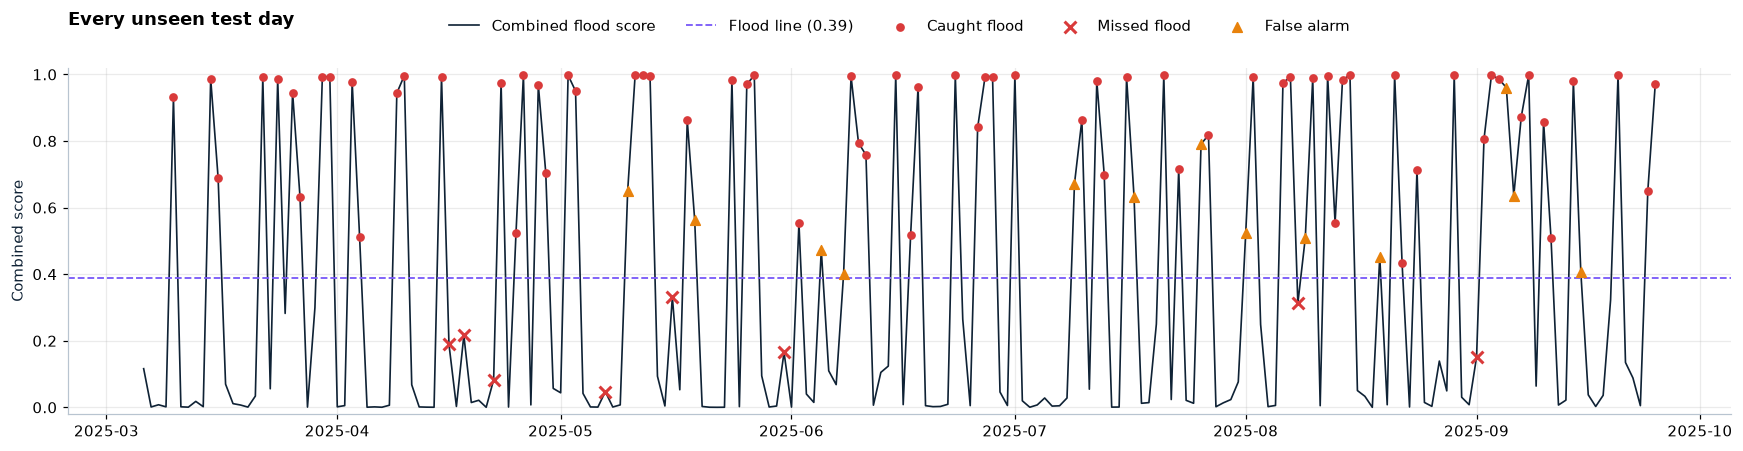

In [38]:
final = scores(y_test, p_sys["test"], TH["sys"])
tn, fp, fn, tp = confusion_matrix(y_test, y_sys).ravel()
display(Markdown(
    f"| Accuracy | Flood recall | Precision | F1 | ROC-AUC | Floods caught | Missed floods | False alarms |\n|---|---|---|---|---|---|---|---|\n"
    f"| **{final['Accuracy']:.1%}** | **{final['Recall']:.1%}** | {final['Precision']:.1%} | {final['F1']:.3f} | {final['ROC-AUC']:.3f} "
    f"| {tp} of {tp + fn} | {fn} | {fp} |"))

fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(dates_test, p_sys["test"], color=C["ink"], lw=1.1, label="Combined flood score")
ax.axhline(TH["sys"], color=C["purple"], ls="--", lw=1.2, label=f"Flood line ({TH['sys']:.2f})")
flood = y_test == 1
ax.scatter(dates_test[flood & (y_sys == 1)], p_sys["test"][flood & (y_sys == 1)], color=C["red"], s=22, zorder=3, label="Caught flood")
ax.scatter(dates_test[flood & (y_sys == 0)], p_sys["test"][flood & (y_sys == 0)], color=C["red"], marker="x", s=60, lw=2, zorder=3, label="Missed flood")
ax.scatter(dates_test[~flood & (y_sys == 1)], p_sys["test"][~flood & (y_sys == 1)], color=C["orange"], marker="^", s=40, zorder=3, label="False alarm")
ax.set_ylim(-0.02, 1.02); ax.set_ylabel("Combined score"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18))
ax.set_title("Every unseen test day", pad=28)
fig.tight_layout(); save(fig, "task10_timeline"); plt.show()

### 10.2 Stability across months and seasons

,Days,Floods,Accuracy,Recall,Precision
month,,,,,
2025-03,26,9,1.000,1.000,1.000
2025-04,30,13,0.900,0.769,1.000
2025-05,31,12,0.839,0.750,0.818
2025-06,30,11,0.933,1.000,0.846
2025-07,31,8,0.903,1.000,0.727
2025-08,31,13,0.871,0.923,0.800
2025-09,25,12,0.840,0.917,0.786


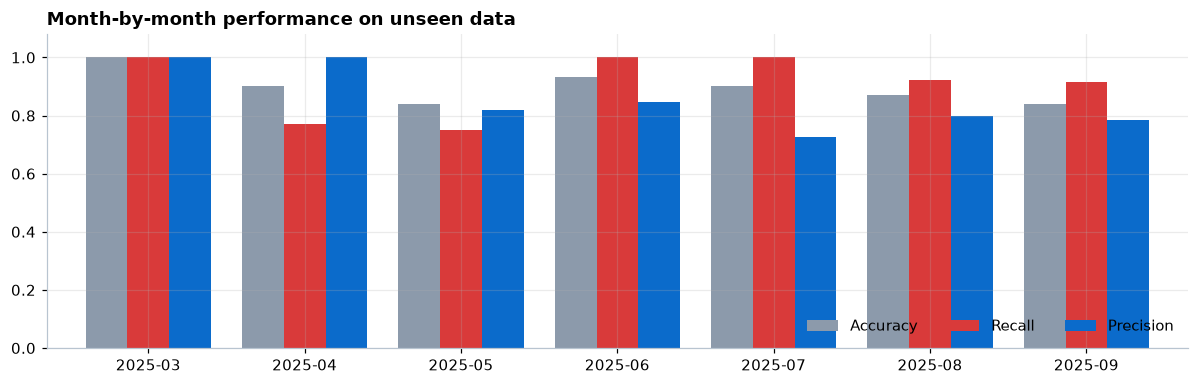

In [39]:
monthly_perf = pd.DataFrame({"month": dates_test.dt.to_period("M").astype(str), "y": y_test, "p": y_sys}).groupby("month").apply(
    lambda g: pd.Series({"Days": len(g), "Floods": g["y"].sum(), "Accuracy": accuracy_score(g["y"], g["p"]),
                         "Recall": recall_score(g["y"], g["p"], zero_division=0),
                         "Precision": precision_score(g["y"], g["p"], zero_division=0)}))
display(table(monthly_perf, gradient=["Recall"], formats={"Days": "{:.0f}", "Floods": "{:.0f}"}))
fig, ax = plt.subplots(figsize=(11, 3.6))
monthly_perf[["Accuracy", "Recall", "Precision"]].plot(kind="bar", ax=ax, width=0.8, color=[C["grey"], C["red"], C["blue"]])
ax.set_ylim(0, 1.08); ax.tick_params(axis="x", rotation=0); ax.set_xlabel(""); ax.legend(ncol=3, loc="lower right")
ax.set_title("Month-by-month performance on unseen data")
fig.tight_layout(); save(fig, "task10_monthly"); plt.show()

### 10.3 Robustness: broken inputs, repeatability and noise
A trustworthy system must **refuse bad input clearly**, give the **same answer twice** and not flip its decision on tiny measurement noise.

In [40]:
good = window_ending(int(idx_test[20]))
def broken(change):
    w = good.copy(); return change(w)
cases = [
    ("Valid 7-day window", good, None),
    ("Only 6 days", good.iloc[1:], "Exactly 7"),
    ("Duplicate date", broken(lambda w: w.assign(date=w["date"].where(w.index != w.index[3], w["date"].iloc[2]))), "Duplicate"),
    ("Gap in dates", broken(lambda w: w.assign(date=w["date"] + pd.to_timedelta([0, 0, 0, 1, 1, 1, 1], unit="D"))), "consecutive"),
    ("Unreadable date", broken(lambda w: w.assign(date=w["date"].astype(str).where(w.index != w.index[0], "not-a-date"))), "Invalid date"),
    ("Missing column", good.drop(columns=["precipitation"]), "Missing columns"),
    ("Text instead of numbers", broken(lambda w: w.assign(soil_moisture="wet")), "no numeric"),
    ("Not a table", "seven days of rain", "table"),
]
rows = []
for name, payload, expected in cases:
    try:
        out = system.predict_window(payload); outcome = f"accepted → {out['Advisory']}"
        ok = expected is None
    except Exception as exc:
        outcome = f"refused: {exc}"; ok = expected is not None and expected.lower() in str(exc).lower()
    rows.append((name, outcome, "PASS" if ok else "FAIL"))
first, second = system.predict_window(good), system.predict_window(good)
rows.append(("Same input twice", f"difference = {abs(first['Combined'] - second['Combined']):.1e}",
             "PASS" if first["Combined"] == second["Combined"] else "FAIL"))

noise_rng = np.random.default_rng(SEED)
flips = []
for _ in range(20):
    noisy = (S_test + noise_rng.normal(0, 0.05, S_test.shape)).astype(np.float32)
    with torch.no_grad():
        pn = 0.5 * predict(lstm, noisy) + 0.5 * rf_on_lstm.predict_proba(embed(noisy))[:, 1]
    flips.append(((pn >= TH["sys"]).astype(int) != y_sys).mean())
rows.append(("±5 % measurement noise (20 runs)", f"decisions changed on {np.mean(flips):.1%} of days",
             "PASS" if np.mean(flips) < 0.05 else "REVIEW"))
tests = pd.DataFrame(rows, columns=["Test", "Outcome", "Result"])
display(tests.style.hide(axis="index").map(lambda v: f"color:{C['green'] if v == 'PASS' else C['red']};font-weight:700", subset=["Result"]))

Test,Outcome,Result
Valid 7-day window,accepted → FLOOD WARNING,PASS
Only 6 days,"refused: Exactly 7 daily rows are required, got 6.",PASS
Duplicate date,refused: Duplicate dates found.,PASS
Gap in dates,refused: Dates must be consecutive days.,PASS
Unreadable date,refused: Invalid date found; use YYYY-MM-DD.,PASS
Missing column,refused: Missing columns: ['precipitation'],PASS
Text instead of numbers,refused: Columns with no numeric values: ['soil_moisture'],PASS
Not a table,refused: Input must be a table (pandas DataFrame).,PASS
Same input twice,difference = 0.0e+00,PASS
±5 % measurement noise (20 runs),decisions changed on 1.0% of days,PASS


### 10.4 Explaining individual decisions with SHAP
A **waterfall plot** starts from the model's average flood probability (bottom) and adds each reading's push towards or away from flood, ending at this day's prediction (top). Shown for one caught flood and one missed flood. It explains the LSTM's score, which supplies half of the combined score and is the input to the Random Forest.

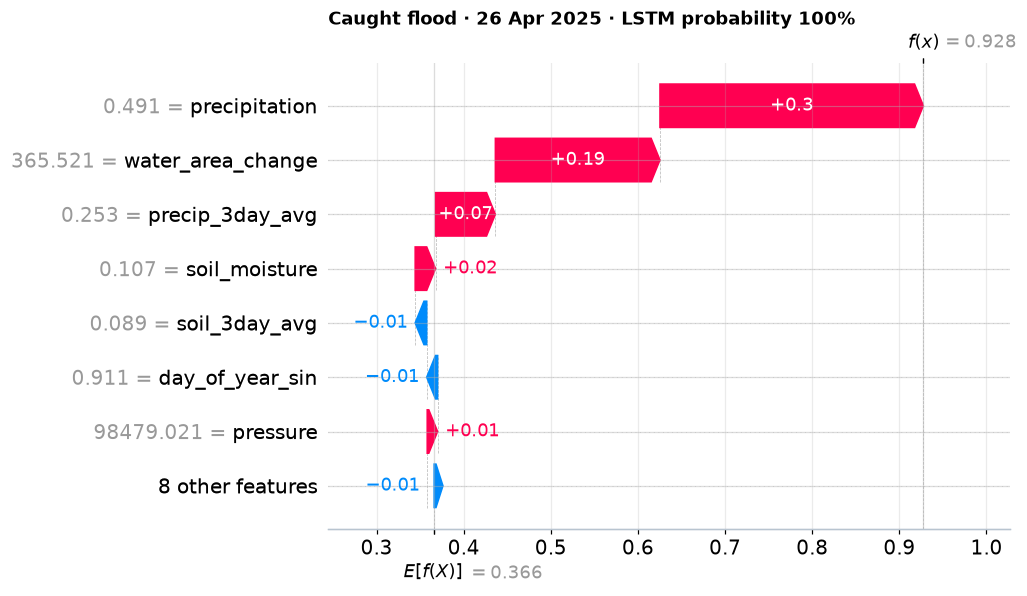

Decision path: facts gathered → rule R1 fired → FLOOD WARNING  (Both models say Flood, or combined score ≥ 75 %)



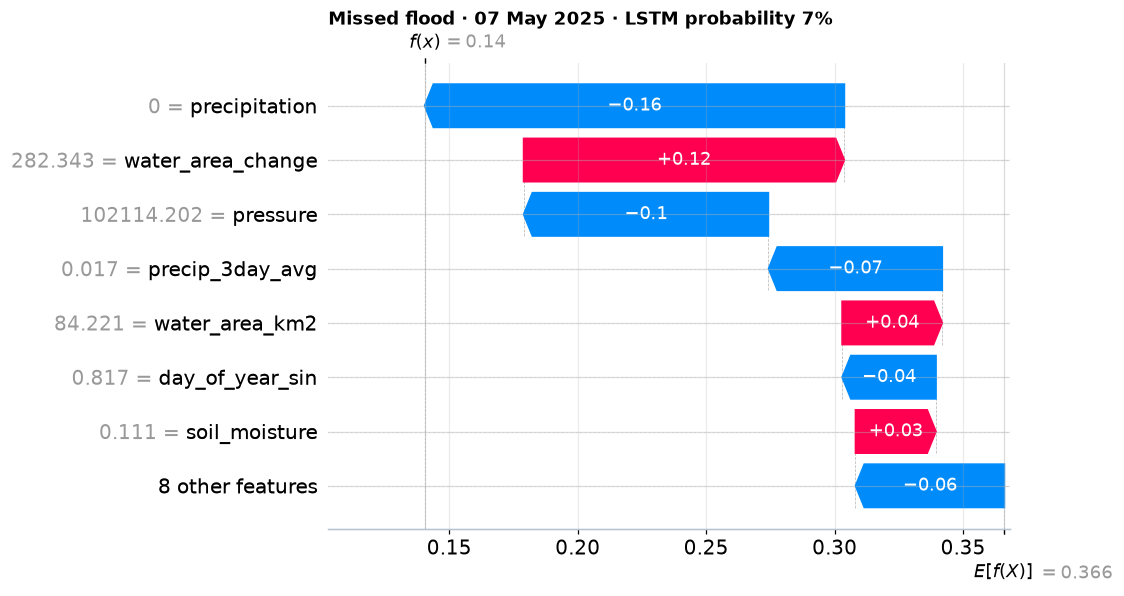

Decision path: facts gathered → rule R3 fired → MONITOR  (Any environmental trigger is active)



In [41]:
raw_last_day = df.iloc[idx_test][SEQ_FEATURES].reset_index(drop=True)
def explain_day(i, title):
    values = lstm_shap[i].sum(0)
    exp = shap.Explanation(values=values, base_values=SHAP_BASE, data=raw_last_day.iloc[i].round(3).to_numpy(),
                           feature_names=SEQ_FEATURES)
    plt.figure()
    shap.plots.waterfall(exp, max_display=8, show=False)
    plt.title(f"{title} · {dates_test[i]:%d %b %Y} · LSTM probability {p_dl['test'][i]:.0%}", loc="left", fontweight="bold")
    save(plt.gcf(), f"task10_shap_{title.split()[0].lower()}"); plt.show()
    r = results.iloc[i]
    print(f"Decision path: facts gathered → rule {r['Rule']} fired → {r['Advisory']}  ({r['Why']})\n")

caught = results.index[(results["Actual"] == "Flood") & (y_sys == 1)]
missed = results.index[(results["Actual"] == "Flood") & (y_sys == 0)]
explain_day(int(results.loc[caught, "Combined"].idxmax()), "Caught flood")
if len(missed):
    explain_day(int(results.loc[missed, "Combined"].idxmin()), "Missed flood")

### 10.5 Ethics, fairness and bias
Not all mistakes are equal: a **missed flood** can cost lives; a **false alarm** costs money and trust ("cry-wolf" effect). Moving the flood line trades one for the other. The curve below is for discussion only: choosing the threshold from test results would leak test information, which is why the real threshold was fixed on validation data.

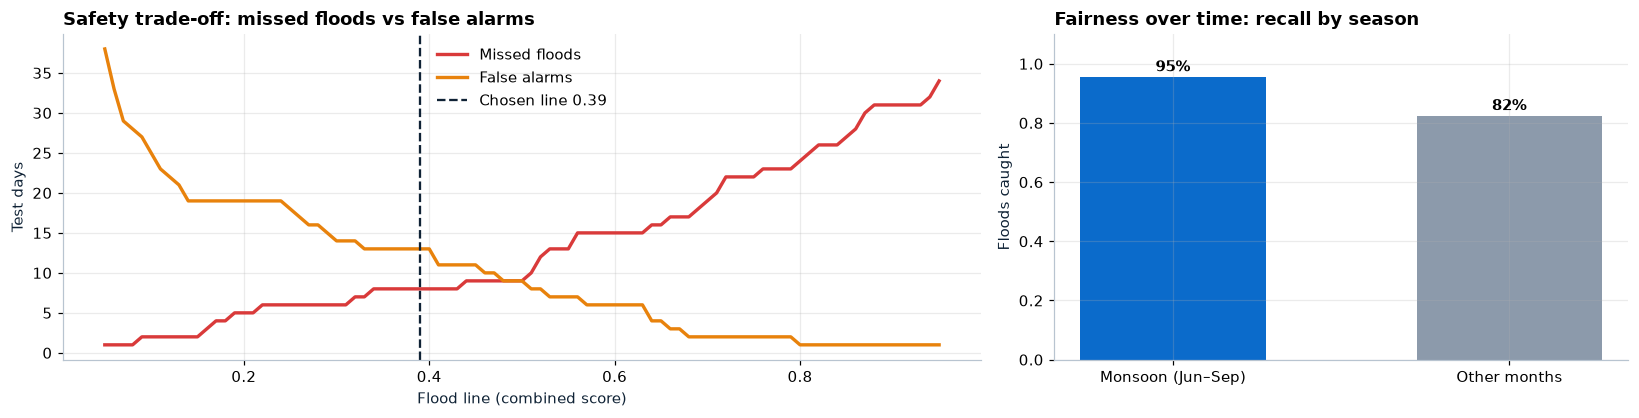

Issue,Evidence from this notebook,Mitigation
Safety,8 floods missed out of 78 (10%),Human review of every advisory; tune the threshold with emergency experts
Target proxy / leakage,One split on water_area_change alone: 89% accuracy; F1 drops sharply without water-area features,Confirm how labels were created; test a true next-day forecast set-up
Label bias,Flood share is ~35% in every month (no monsoon peak),Replace with verified flood records from official agencies
Geographic fairness,"All data from one point (19.0°N, 73.0°E)",Validate on other regions before any wider use
Fairness over time,Recall 82%–95% across seasons; monthly recall 75%–100%,Monitor performance per season after deployment
Fairness across people,No demographic or vulnerability data in the dataset,Cannot be measured here; must be assessed with communities
Transparency,"Every advisory names its rule; SHAP, permutation and ablation explain the scores",Keep explanations visible to users
Privacy,Only environmental readings; no personal data,Keep it that way


In [42]:
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
fn_curve = [int(((p_sys["test"] < t) & (y_test == 1)).sum()) for t in grid_t]
fp_curve = [int(((p_sys["test"] >= t) & (y_test == 0)).sum()) for t in grid_t]
season = np.where(dates_test.dt.month.isin([6, 7, 8, 9]), "Monsoon (Jun–Sep)", "Other months")
season_recall = pd.Series({s: recall_score(y_test[season == s], y_sys[season == s], zero_division=0) for s in np.unique(season)})

fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(grid_t, fn_curve, color=C["red"], lw=2.2, label="Missed floods")
axes[0].plot(grid_t, fp_curve, color=C["orange"], lw=2.2, label="False alarms")
axes[0].axvline(TH["sys"], color=C["ink"], ls="--", label=f"Chosen line {TH['sys']:.2f}")
axes[0].set_xlabel("Flood line (combined score)"); axes[0].set_ylabel("Test days"); axes[0].legend()
axes[0].set_title("Safety trade-off: missed floods vs false alarms")
axes[1].bar(season_recall.index, season_recall.values, color=[C["blue"], C["grey"]], width=0.55)
for i, v in enumerate(season_recall.values):
    axes[1].text(i, v + 0.02, f"{v:.0%}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 1.1); axes[1].set_ylabel("Floods caught"); axes[1].set_title("Fairness over time: recall by season")
fig.tight_layout(); save(fig, "task10_ethics"); plt.show()

lat, lon = raw["latitude"].iloc[0], raw["longitude"].iloc[0]
ethics = pd.DataFrame([
    ["Safety", f"{fn} floods missed out of {tp + fn} ({fn / (tp + fn):.0%})", "Human review of every advisory; tune the threshold with emergency experts"],
    ["Target proxy / leakage", f"One split on {PROXY_FEATURE} alone: {PROXY_ACC:.0%} accuracy; F1 drops sharply without water-area features",
     "Confirm how labels were created; test a true next-day forecast set-up"],
    ["Label bias", f"Flood share is ~{monthly['flood_rate'].mean():.0%} in every month (no monsoon peak)", "Replace with verified flood records from official agencies"],
    ["Geographic fairness", f"All data from one point ({lat}°N, {lon}°E)", "Validate on other regions before any wider use"],
    ["Fairness over time", f"Recall {season_recall.min():.0%}–{season_recall.max():.0%} across seasons; monthly recall {monthly_perf['Recall'].min():.0%}–{monthly_perf['Recall'].max():.0%}",
     "Monitor performance per season after deployment"],
    ["Fairness across people", "No demographic or vulnerability data in the dataset", "Cannot be measured here; must be assessed with communities"],
    ["Transparency", "Every advisory names its rule; SHAP, permutation and ablation explain the scores", "Keep explanations visible to users"],
    ["Privacy", "Only environmental readings; no personal data", "Keep it that way"],
], columns=["Issue", "Evidence from this notebook", "Mitigation"])
display(ethics.style.hide(axis="index").set_properties(**{"text-align": "left"}))

### 10.6 Deployment
The trained components are saved as files and served by the **FloodSense** website (Streamlit), deployed free on **Streamlit Community Cloud** from the GitHub repository [`Stavan1234/FloodSense`](https://github.com/Stavan1234/FloodSense). Any visitor can pick a day, get an advisory with its explanation, play with what-if sliders and see the validation evidence. The website loads **exactly the model trained in this notebook** (the files written by the cell below), so its numbers match this run.

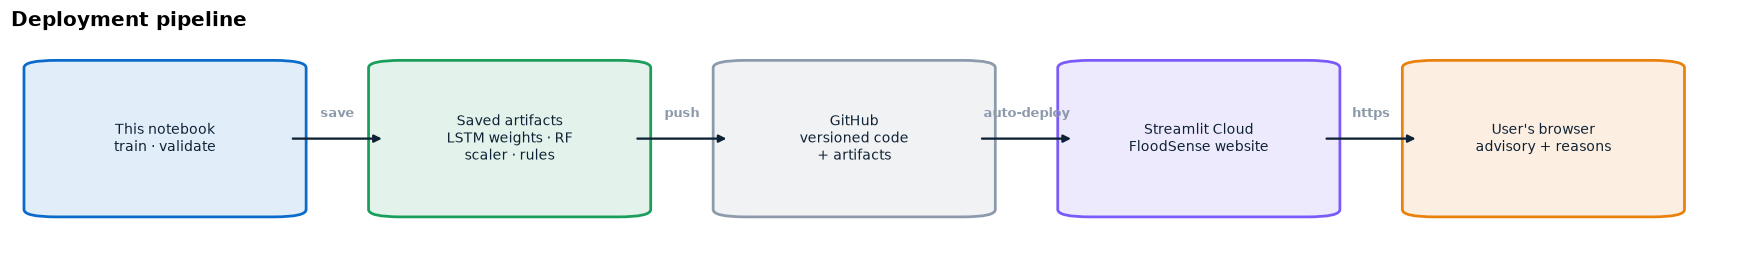

Website files written → model_artifacts/ and site_data/
Saved 30 files (figures, tables, model) → FloodSense_Practicals_4_to_10_outputs.zip


In [43]:
fig, ax = plt.subplots(figsize=(16, 2.4))
boxes = {
    "nb":  (0.00, 0.30, 0.15, 0.40, "This notebook\ntrain · validate", C["blue"]),
    "art": (0.2125, 0.30, 0.15, 0.40, "Saved artifacts\nLSTM weights · RF\nscaler · rules", C["green"]),
    "git": (0.425, 0.30, 0.15, 0.40, "GitHub\nversioned code\n+ artifacts", C["grey"]),
    "web": (0.6375, 0.30, 0.15, 0.40, "Streamlit Cloud\nFloodSense website", C["purple"]),
    "usr": (0.85, 0.30, 0.15, 0.40, "User's browser\nadvisory + reasons", C["orange"]),
}
draw_flow(ax, boxes, [("nb", "art", "save", ""), ("art", "git", "push", ""), ("git", "web", "auto-deploy", ""), ("web", "usr", "https", "")],
          "Deployment pipeline")
fig.tight_layout(); save(fig, "task10_deployment"); plt.show()

# Files the FloodSense website loads: the same model and the same numbers as this run.
site_model, site_data = Path("model_artifacts"), Path("site_data")
site_model.mkdir(exist_ok=True); site_data.mkdir(exist_ok=True)
torch.save({"state_dict": lstm.state_dict(), "n_features": len(SEQ_FEATURES),
            "hidden": lstm.lstm.hidden_size, "dropout": lstm.dropout.p}, site_model / "lstm.pt")
joblib.dump({"rf": rf_on_lstm, "imputer": seq_imputer, "scaler": seq_scaler, "env_features": ENV,
             "features": SEQ_FEATURES, "window": WINDOW, "thresholds": TH, "rule_levels": RULE_LEVELS,
             "watch_level": WATCH_LEVEL, "shap_background": background.numpy(), "shap_base": SHAP_BASE},
            site_model / "system.joblib")
df[["date"] + ENV + ["soil_type", TARGET]].to_csv(site_data / "clean_dataset.csv", index=False)
results.assign(Triggers=results["Triggers"].map(";".join)).to_csv(site_data / "test_predictions.csv", index=False)
pd.DataFrame({"feature": SEQ_FEATURES, "mean_abs_shap": np.abs(lstm_shap.sum(1)).mean(0)}).to_csv(site_data / "shap_features.csv", index=False)
pd.DataFrame({"day": day_labels, "mean_abs_shap": np.abs(lstm_shap.sum(2)).mean(0)}).to_csv(site_data / "shap_days.csv", index=False)
monthly_perf.to_csv(site_data / "monthly_performance.csv")
tests.to_csv(site_data / "robustness_tests.csv", index=False)
summary_json = {
    "splits": {name: [str(df["date"].iloc[ix[0]].date()), str(df["date"].iloc[ix[-1]].date())]
               for name, ix in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]},
    "metrics": {k: float(v) for k, v in final.items()},
    "confusion": {"tp": int(tp), "fn": int(fn), "fp": int(fp), "tn": int(tn)},
    "lstm_config": BEST_LSTM,
    "components": {name: {k: float(v) for k, v in row.items()} for name, row in components.drop(columns="Threshold").iterrows()},
}
(site_data / "summary.json").write_text(json.dumps(summary_json, indent=2), encoding="utf-8")
print(f"Website files written → {site_model}/ and {site_data}/")

archive = Path("FloodSense_Practicals_4_to_10_outputs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUT.rglob("*"):
        if path.is_file():
            zf.write(path, str(path))
print(f"Saved {sum(1 for p in OUT.rglob('*') if p.is_file())} files (figures, tables, model) → {archive}")

DOWNLOAD_OUTPUTS = False   # set True to download the ZIP in Colab
if DOWNLOAD_OUTPUTS:
    from google.colab import files
    files.download(str(archive))

### 10.7 Summary

In [44]:
summary = pd.DataFrame([
    ["4 · EDA & cleaning", f"{len(df):,} clean daily records; 7 data problems found and fixed", "Single location; flat monthly labels"],
    ["5 · Features", f"{TOP_K} features selected (MI + RF); chronological 70/15/15 split", f"{PROXY_FEATURE} alone: {PROXY_ACC:.0%}"],
    ["6 · Machine learning", f"Best: {BEST_ML} · F1 {ml_results.loc[BEST_ML, 'F1']:.2f}", f"SHAP top feature: {rf_shap_rank.index[0]}"],
    ["7 · Deep learning", f"{BEST_LSTM} · F1 {dl_results.loc[BEST_LSTM, 'F1']:.2f}", f"Dense baseline F1 {dl_results.loc['Dense baseline', 'F1']:.2f}"],
    ["8 · Interpretability", f"Top reading: {perm['LSTM'].idxmax()} · key day: {time_imp['LSTM'].idxmax()}", "Permutation, ablation, activations, SHAP"],
    ["9 · Integration", f"DL → ML → AI rules · F1 {components.loc['Integrated score (DL+ML)', 'F1']:.2f}", "Every advisory names its rule"],
    ["10 · Validation", f"Accuracy {final['Accuracy']:.1%} · recall {final['Recall']:.1%} · {fn} missed floods",
     f"{(tests['Result'] == 'PASS').sum()}/{len(tests)} robustness tests passed"],
], columns=["Task", "Result", "Note"])
display(summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Task,Result,Note
4 · EDA & cleaning,"1,364 clean daily records; 7 data problems found and fixed",Single location; flat monthly labels
5 · Features,10 features selected (MI + RF); chronological 70/15/15 split,water_area_change alone: 89%
6 · Machine learning,Best: Decision Tree · F1 0.99,SHAP top feature: water_area_change
7 · Deep learning,LSTM 32 units · dropout 0.3 · F1 0.88,Dense baseline F1 0.87
8 · Interpretability,Top reading: water_area_change · key day: Target day,"Permutation, ablation, activations, SHAP"
9 · Integration,DL → ML → AI rules · F1 0.87,Every advisory names its rule
10 · Validation,Accuracy 89.7% · recall 89.7% · 8 missed floods,10/10 robustness tests passed


### Conclusion
The project went from a raw, flawed CSV to a **validated, explainable and deployed** intelligent system. A deep-learning model learns a summary of each week, a machine-learning model predicts from that summary, and a transparent rule engine turns the scores into advisories that state their reasons. Performance on unseen days is strong, but the evidence also shows **why it must not be used for real emergencies**: the labels look simulated, the most relied-on signal (water area) may be the flood itself rather than a predictor, and all data comes from one location. These limitations are documented openly, as responsible-AI practice requires.

> ⚠️ Educational prototype: same-day classification on an educational dataset. Not an official flood-warning service.